# **Project context**

The project simulates a hypothetical ANDV outbreak in an Italian coastal community of about 10,000 inhabitants. The research questions are:

1. How does an ANDV outbreak evolve in the absence of intervention, and what epidemic burden is expected under the epidemiological characteristics observed during the Epuyén outbreak?

2. To what extent can symptomatic isolation reduce epidemic size and peak prevalence when diagnosis is subject to realistic delays, and under what conditions can isolation alone achieve epidemic control?

3. Can contact tracing and quarantine reduce transmission below the epidemic threshold, and how do analytical control thresholds compare with outbreak risk on an explicit contact network?

# 0. Setup: imports, parameters and calibration

In [1]:
import os
import time
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.integrate import solve_ivp
from scipy.ndimage import uniform_filter1d
import networkx as nx
import scipy.sparse as sp
from IPython.display import Image, display

%matplotlib inline

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})

OUTPUT_DIR = Path('.')
RANDOM_SEED = 2026
np.random.seed(RANDOM_SEED)


## Parameters (with literature sources)

Each parameter is linked to the epidemiological assumption used in the model.

| Parameter | Value | Unit | Rationale |
|---|---:|---:|---|
| N | 10,000 | people | Number of individuals. |
| R_0 | 2.12 | dimensionless | Pre-control median reproductive number reported for the Epuyen ANDV outbreak. Since early outbreak depletion is negligible, $R_{ef}\approx R_0$. |
| σ | 1/18 | day$^{-1}$ | Median incubation period of 18 days for Andes-virus HCPS. |
| γ | 1/5 | day$^{-1}$ | Approximate duration of symptomatic infectiousness before recovery/isolation; consistent with a serial interval around 23 days and an 18-day incubation period. |
| ε | 1.0 | dimensionless | Conservative assumption: exposed/pre-symptomatic individuals are  as infectious as symptomatic individuals. |
|  ⁠β | calibrated | day$^{-1}$ | Derived analytically using the Next Generation Matrix: $\beta = R_0/(\epsilon/\sigma + 1/\gamma)$. |

The same parameters are then reused in the isolation, contact tracing and network simulations, so that scenarios are comparable.

In [2]:
# Epidemiological parameters ---------------------------------------------------
# Sources: R0 & serial interval -> Martinez et al. 2020 (NEJM, Epuyen 2018);
# incubation median 18 d -> Vial et al. 2006; pre-symptomatic viraemia -> Ferres et al. 2007.

R0_target = 2.12          # Pre-control reproduction number, Epuyen 2018 (Martinez et al. 2020).

sigma = 1 / 18            # E -> I rate; incubation median 18 d (Vial et al. 2006).
gamma = 1 / 5             # I -> R rate; serial interval 23 d - incubation 18 d (Martinez et al. 2020).
epsilon = 1.0             # Pre-symptomatic relative infectivity (parsimonious assumption; viraemia pre-onset, Ferres et al. 2007).
CFR = 0.32                # Case-fatality ratio; Epuyen 2018 (Martinez et al. 2020). Range 21-50% across Argentina/Chile (Ferres et al. 2007).

# Population -------------------------------------------------------------------
N = 10_000                # Community size.

# Initial conditions -----------------------------------------------------------
I0 = 1                    # One index case.
E0 = 0
R0_pop = 0
S0 = N - I0 - E0 - R0_pop

# Simulation horizon -----------------------------------------------------------
T_days = 400
t_eval = np.linspace(0, T_days, T_days * 10)


## Calibration of β via the next-generation matrix

In a SEIR model with pre-symptomatic infectivity, the force of infection is

$$\lambda = \beta \frac{\epsilon E + I}{N}.$$

A newly infected individual contributes infections while exposed for an average duration $1/\sigma$, with relative infectivity $\epsilon$, and while symptomatic for an average duration $1/\gamma$. Therefore,

$$R_0 = \beta \left( \frac{\epsilon}{\sigma} + \frac{1}{\gamma} \right).$$

Solving for $\beta$ gives

$$\beta = \frac{R_0}{\epsilon/\sigma + 1/\gamma}.$$


In [3]:
# Analytical calibration of beta ------------------------------------------------
beta = R0_target / (epsilon / sigma + 1 / gamma)
R0_check = beta * (epsilon / sigma + 1 / gamma)

print(f"Calibrated beta      = {beta:.4f} day^-1")
print(f"Target R0            = {R0_target:.4f}")
print(f"Verified R0          = {R0_check:.4f}  {'OK' if abs(R0_check - R0_target) < 1e-10 else 'ERROR'}")
print()
print(f"Latent period        = {1/sigma:.1f} days  (sigma = {sigma:.4f} day^-1)")
print(f"Infectious period    = {1/gamma:.1f} days  (gamma = {gamma:.4f} day^-1)")
print(f"Baseline epsilon     = {epsilon}")


Calibrated beta      = 0.0922 day^-1
Target R0            = 2.1200
Verified R0          = 2.1200  OK

Latent period        = 18.0 days  (sigma = 0.0556 day^-1)
Infectious period    = 5.0 days  (gamma = 0.2000 day^-1)
Baseline epsilon     = 1.0


# 1. Deterministic SEIR/SEIQR model (mean-field benchmark)

The ODE model assumes homogeneous mixing. It is fast and analytically transparent, so it serves as the benchmark: it establishes the no-intervention dynamics and the order-of-magnitude effect of each measure, against which the realistic network model (Part 3) is later compared.

## 1.1 Baseline epidemic (SEIR with pre-symptomatic infectivity)

The baseline model is

$$\frac{dS}{dt} = -\beta \frac{\epsilon E + I}{N} S,$$

$$\frac{dE}{dt} = \beta \frac{\epsilon E + I}{N} S - \sigma E,$$

$$\frac{dI}{dt} = \sigma E - \gamma I,$$

$$\frac{dR}{dt} = \gamma I.$$

The term $\epsilon E$ extends the standard infection pressure $\beta I/N$ by allowing exposed individuals to contribute to transmission before symptom onset.


### SEIR equations with pre-symptomatic infectivity

In [4]:
def seir_presymp(t, y, beta, sigma, gamma, epsilon, N):
    """
    SEIR model with pre-symptomatic infectivity.

    Parameters
    ----------
    beta : float
        Transmission rate [day^-1].
    sigma : float
        E -> I transition rate [day^-1].
    gamma : float
        Recovery/removal rate [day^-1].
    epsilon : float
        Relative infectivity of exposed individuals.
    N : int
        Total population size.
    """
    S, E, I, R = y
    infection_force = beta * (epsilon * E + I) / N
    dS = -infection_force * S
    dE = infection_force * S - sigma * E
    dI = sigma * E - gamma * I
    dR = gamma * I
    return [dS, dE, dI, dR]


### Simulation of the baseline

In [5]:
# Scenario 1 simulation --------------------------------------------------------
y0 = [S0, E0, I0, R0_pop]

sol = solve_ivp(
    fun=seir_presymp,
    t_span=(0, T_days),
    y0=y0,
    t_eval=t_eval,
    args=(beta, sigma, gamma, epsilon, N),
    method='RK45',
    rtol=1e-8,
    atol=1e-10,
)

S_sol, E_sol, I_sol, R_sol = sol.y
t_sol = sol.t

print(f"Integration completed: {sol.message}")
print(f"Number of time points: {len(t_sol)}")


Integration completed: The solver successfully reached the end of the integration interval.
Number of time points: 4000


### Summary statistics

In [6]:
peak_I_idx = np.argmax(I_sol)
peak_I_val = I_sol[peak_I_idx]
peak_I_day = t_sol[peak_I_idx]
attack_rate = R_sol[-1] / N
final_size = int(R_sol[-1])

print("=" * 54)
print("  SIMULATION RESULTS - SCENARIO 1 (BASELINE)")
print("=" * 54)
print(f"  R0                  = {R0_check:.2f}")
print(f"  calibrated beta     = {beta:.4f} day^-1")
print(f"  peak I              = {peak_I_val:.0f} people  (day {peak_I_day:.0f})")
print(f"  final attack rate   = {attack_rate:.1%}")
print(f"  total cases         = {final_size} of {N}")
print("=" * 54)
print()
print("Population conservation check:")
print(f"  S+E+I+R at t=0      = {S_sol[0]+E_sol[0]+I_sol[0]+R_sol[0]:.2f}")
print(f"  S+E+I+R at t=T      = {S_sol[-1]+E_sol[-1]+I_sol[-1]+R_sol[-1]:.2f}  (expected: {N})")


  SIMULATION RESULTS - SCENARIO 1 (BASELINE)
  R0                  = 2.12
  calibrated beta     = 0.0922 day^-1
  peak I              = 450 people  (day 186)
  final attack rate   = 82.6%
  total cases         = 8261 of 10000

Population conservation check:
  S+E+I+R at t=0      = 10000.00
  S+E+I+R at t=T      = 10000.00  (expected: 10000)


### Epidemic curve

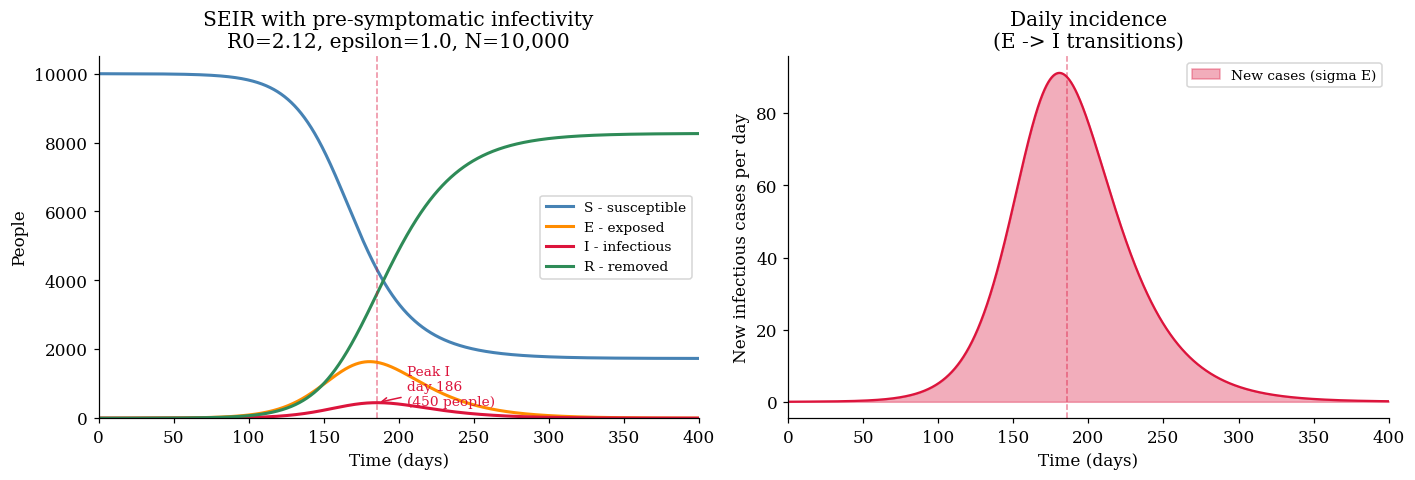

Saved figure: B1_SEIR_baseline.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor='white')

# Left panel: compartments -----------------------------------------------------
ax = axes[0]
ax.plot(t_sol, S_sol, color='steelblue', lw=2, label='S - susceptible')
ax.plot(t_sol, E_sol, color='darkorange', lw=2, label='E - exposed')
ax.plot(t_sol, I_sol, color='crimson', lw=2, label='I - infectious')
ax.plot(t_sol, R_sol, color='seagreen', lw=2, label='R - removed')
ax.axvline(peak_I_day, color='crimson', lw=1, ls='--', alpha=0.5)
ax.annotate(
    f'Peak I\nday {peak_I_day:.0f}\n({peak_I_val:.0f} people)',
    xy=(peak_I_day, peak_I_val),
    xytext=(peak_I_day + 20, peak_I_val * 0.85),
    fontsize=9,
    color='crimson',
    arrowprops=dict(arrowstyle='->', color='crimson', lw=1),
)
ax.set_xlabel('Time (days)')
ax.set_ylabel('People')
ax.set_title(f'SEIR with pre-symptomatic infectivity\nR0={R0_check:.2f}, epsilon={epsilon}, N={N:,}')
ax.legend(fontsize=9, loc='center right')
ax.set_xlim(0, T_days)
ax.set_ylim(0, N * 1.05)

# Right panel: daily incidence -------------------------------------------------
new_cases = sigma * E_sol
ax2 = axes[1]
ax2.fill_between(t_sol, new_cases, color='crimson', alpha=0.35, label='New cases (sigma E)')
ax2.plot(t_sol, new_cases, color='crimson', lw=1.5)
ax2.axvline(peak_I_day, color='crimson', lw=1, ls='--', alpha=0.5)
ax2.set_xlabel('Time (days)')
ax2.set_ylabel('New infectious cases per day')
ax2.set_title('Daily incidence\n(E -> I transitions)')
ax2.legend(fontsize=9)
ax2.set_xlim(0, T_days)

plt.tight_layout()
plt.savefig('B1_SEIR_baseline.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B1_SEIR_baseline.png')


### Internal check: serial interval

The Epuyen outbreak reports a serial interval of approximately **23 +/- 7 days**. In this model, a rough approximation is

$$SI_{model} \approx \frac{1}{\sigma} + \text{short delay to transmission after symptom onset}.$$

With $1/\sigma \approx 22$ days and early symptomatic transmission approximated by one additional day, the model gives roughly 23 days, consistent with the outbreak estimate.

In [8]:
SI_model_approx = 1 / sigma + 1 / gamma   # generation interval = latent + infectious period
SI_observed = 23
SI_sd_observed = 7
compat = abs(SI_model_approx - SI_observed) <= SI_sd_observed

print(f"Approximate model serial interval = {SI_model_approx:.1f} days")
print(f"Observed serial interval          = {SI_observed} +/- {SI_sd_observed} days")
print(f"Compatible with observed range: {'YES' if compat else 'NO'}")
print()

print('FINAL PARAMETER SUMMARY - B1 SEIR BASELINE')
print('-' * 62)
print(f"{'Parameter':<18} {'Value':<14} {'Source / rationale':<30}")
print('-' * 62)
print(f"{'R0':<18} {R0_target:<14} {'Epuyen ANDV outbreak':<30}")
print(f"{'sigma':<18} {sigma:<14.4f} {'incubation timing':<30}")
print(f"{'gamma':<18} {gamma:<14.4f} {'clinical infectious period':<30}")
print(f"{'epsilon':<18} {epsilon:<14} {'pre-symptomatic viremia':<30}")
print(f"{'beta':<18} {beta:<14.4f} {'NGM calibration':<30}")
print(f"{'N':<18} {N:<14} {'project population':<30}")
print('-' * 62)


Approximate model serial interval = 23.0 days
Observed serial interval          = 23 +/- 7 days
Compatible with observed range: YES

FINAL PARAMETER SUMMARY - B1 SEIR BASELINE
--------------------------------------------------------------
Parameter          Value          Source / rationale            
--------------------------------------------------------------
R0                 2.12           Epuyen ANDV outbreak          
sigma              0.0556         incubation timing             
gamma              0.2000         clinical infectious period    
epsilon            1.0            pre-symptomatic viremia       
beta               0.0922         NGM calibration               
N                  10000          project population            
--------------------------------------------------------------


### Conclusion — Baseline
The calibrated SEIR gives the no-intervention reference: a large but slow epidemic (about 83% attack rate, peak near day 186). It is the benchmark against which every intervention is measured, and it confirms the outbreak does not self-extinguish in mean field. (Early on R0 ≈ R_eff since S/N ≈ 1; γ = 1/5 is a deliberately conservative infectious period, not a mechanical 'serial interval − incubation'.)

## 1.2 Adding symptomatic isolation

**Question.** How much can rapid symptomatic isolation reduce the epidemic, and is there a diagnostic delay $\tau^*$ that makes $R_0^{eff}<1$?

We add a quarantine/isolation compartment $Q$:

- $dS/dt = -\beta(\epsilon E+I)S/N$
- $dE/dt = \beta(\epsilon E+I)S/N - \sigma E$
- $dI/dt = \sigma E - (\gamma + \delta)I$
- $dQ/dt = \delta I - \gamma Q$
- $dR/dt = \gamma(I + Q)$

where $\delta = 1/\tau$. Individuals in $Q$ do not transmit.

The effective reproduction number under isolation is

$$R_0^{iso}(\tau) = \beta \left( \frac{\epsilon}{\sigma} + \frac{1}{\gamma+\delta} \right).$$

In [9]:
tau_baseline = 5
# Diagnostic/isolation delay values to test, in days.
tau_values = [1, 2, 3, 5, 7, 10, 14]

print('tau_baseline =', tau_baseline, 'days')
print('delta_base   =', round(1 / tau_baseline, 4), 'day^-1')
print('beta         =', round(beta, 4), 'day^-1')


tau_baseline = 5 days
delta_base   = 0.2 day^-1
beta         = 0.0922 day^-1


In [10]:
def seir_isolation(t, y, beta, sigma, gamma, epsilon, delta, N):
    """SEIR model with symptomatic isolation compartment Q."""
    S, E, I, Q, R = y
    infection_force = beta * (epsilon * E + I) / N
    dS = -infection_force * S
    dE = infection_force * S - sigma * E
    dI = sigma * E - (gamma + delta) * I
    dQ = delta * I - gamma * Q
    dR = gamma * (I + Q)
    return [dS, dE, dI, dQ, dR]


In [11]:
results_s2 = {}
for tau in tau_values:
    delta = 1 / tau
    y0_s2 = [N - 1, 0, 1, 0, 0]
    sol2 = solve_ivp(
        seir_isolation, (0, T_days), y0_s2, t_eval=t_eval,
        args=(beta, sigma, gamma, epsilon, delta, N),
        method='RK45', rtol=1e-8, atol=1e-10,
    )
    S2, E2, I2, Q2, R2 = sol2.y
    R0_eff = beta * (epsilon / sigma + 1 / (gamma + delta))
    results_s2[tau] = {
        't': sol2.t, 'S': S2, 'E': E2, 'I': I2, 'Q': Q2, 'R': R2,
        'R0_eff': R0_eff,
        'attack_rate': R2[-1] / N,
        'peak_I': I2.max(),
        'peak_day': sol2.t[I2.argmax()],
    }

# Critical tau calculation.
residual = 1 / beta - epsilon / sigma
if residual > 0:
    delta_crit = 1 / residual - gamma
    tau_crit = 1 / delta_crit if delta_crit > 0 else float('inf')
else:
    tau_crit = float('inf')

print(f"{'tau':>8} {'delta':>10} {'R0_eff':>10} {'Attack%':>10} {'Peak I':>9} {'Peak day':>10}")
print('-' * 67)
ar0 = R_sol[-1] / N
print(f"{'no iso':>8} {'0.0000':>10} {R0_target:>10.4f} {ar0:>9.1%} {I_sol.max():>9.0f} {t_sol[I_sol.argmax()]:>10.0f}")
for tau, r in sorted(results_s2.items()):
    print(f"{tau:>8} {1/tau:>10.4f} {r['R0_eff']:>10.4f} {r['attack_rate']:>9.1%} {r['peak_I']:>9.0f} {r['peak_day']:>10.0f}")
print()
print(f'Critical tau for R0_eff=1: {tau_crit:.2f} days')
print('Conclusion: realistic symptomatic isolation alone is not enough; contact tracing is needed.')


     tau      delta     R0_eff    Attack%    Peak I   Peak day
-------------------------------------------------------------------
  no iso     0.0000     2.1200     82.6%       450        186
       1     1.0000     1.7359     68.2%        49        276
       2     0.5000     1.7908     71.9%        92        250
       3     0.3333     1.8320     73.8%       127        236
       5     0.2000     1.8896     76.1%       183        221
       7     0.1429     1.9280     77.4%       222        212
      10     0.1000     1.9664     78.6%       264        205
      14     0.0714     1.9987     79.5%       301        200

Critical tau for R0_eff=1: inf days
Conclusion: realistic symptomatic isolation alone is not enough; contact tracing is needed.


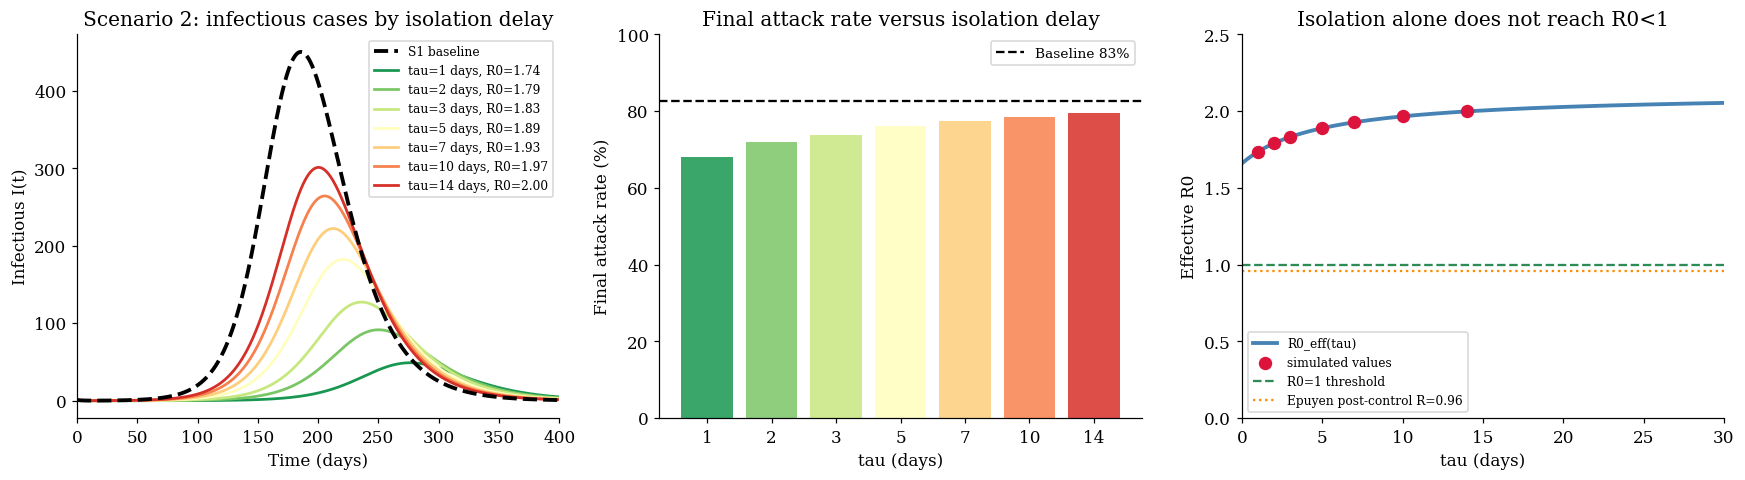

Saved figure: B2_SEIR_isolation.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), facecolor='white')
colors = cm.RdYlGn_r(np.linspace(0.1, 0.9, len(tau_values)))

# Panel 1: infectious curve by tau.
ax = axes[0]
ax.plot(t_sol, I_sol, 'k', lw=2.5, ls='--', label='S1 baseline', zorder=5)
for (tau, res), col in zip(sorted(results_s2.items()), colors):
    ax.plot(res['t'], res['I'], color=col, lw=1.8, label=f'tau={tau} days, R0={res["R0_eff"]:.2f}')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Infectious I(t)')
ax.set_title('Scenario 2: infectious cases by isolation delay')
ax.legend(fontsize=8)
ax.set_xlim(0, T_days)

# Panel 2: final attack rate.
ax2 = axes[1]
taus_p = sorted(results_s2.keys())
ar_p = [results_s2[t]['attack_rate'] * 100 for t in taus_p]
ax2.bar(range(len(taus_p)), ar_p, color=[cm.RdYlGn_r(x) for x in np.linspace(0.1, 0.9, len(taus_p))], alpha=0.85)
ax2.axhline(R_sol[-1] / N * 100, color='k', ls='--', lw=1.5, label=f'Baseline {R_sol[-1]/N:.0%}')
ax2.set_xticks(range(len(taus_p)))
ax2.set_xticklabels([str(t) for t in taus_p])
ax2.set_xlabel('tau (days)')
ax2.set_ylabel('Final attack rate (%)')
ax2.set_title('Final attack rate versus isolation delay')
ax2.legend(fontsize=9)
ax2.set_ylim(0, 100)

# Panel 3: R0_eff curve.
ax3 = axes[2]
tau_c = np.linspace(0.1, 30, 500)
r0_c = beta * (epsilon / sigma + 1 / (gamma + 1 / tau_c))
ax3.plot(tau_c, r0_c, 'steelblue', lw=2.5, label='R0_eff(tau)')
ax3.scatter(taus_p, [results_s2[t]['R0_eff'] for t in taus_p], color='crimson', s=60, zorder=5, label='simulated values')
ax3.axhline(1.0, color='seagreen', ls='--', lw=1.5, label='R0=1 threshold')
ax3.axhline(0.96, color='darkorange', ls=':', lw=1.5, label='Epuyen post-control R=0.96')
ax3.fill_between(tau_c, 0, 1, where=(r0_c < 1), alpha=0.1, color='seagreen')
ax3.set_xlabel('tau (days)')
ax3.set_ylabel('Effective R0')
ax3.set_title('Isolation alone does not reach R0<1')
ax3.legend(fontsize=8)
ax3.set_xlim(0, 30)
ax3.set_ylim(0, 2.5)

plt.tight_layout()
plt.savefig('B2_SEIR_isolation.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B2_SEIR_isolation.png')


### Conclusion — Isolation
Isolating symptomatic cases only flattens the curve: β is unchanged (isolation shortens the time spent transmitting, not biological transmissibility), and because pre-symptomatic spread persists, no realistic diagnostic delay τ brings R_eff below 1. The Epuyén post-intervention R ≈ 0.96 reflected isolation AND contact quarantine, not isolation alone — which is exactly why contact tracing (Scenario 3) is needed.

### The ε* threshold: when can isolation work?

Even with instantaneous symptomatic isolation ($\delta\to\infty$), transmission from the exposed/pre-symptomatic compartment remains. The minimum reproduction number under symptomatic isolation alone is

$$R_0^{min} = \beta\frac{\epsilon}{\sigma}.$$

Setting $R_0^{min}=1$ gives

$$\epsilon^* = \frac{\sigma}{\beta}.$$

- If $\epsilon < \epsilon^*$, isolation could in principle contain the epidemic.
- If $\epsilon > \epsilon^*$, isolation alone cannot contain the epidemic, because exposed individuals generate enough secondary infections before symptoms appear.

Numerically $\epsilon^* = \sigma/\beta \approx 0.60$. Since the baseline $\epsilon = 1 > 0.60$, pre-symptomatic transmission alone keeps $R_0$ above one, so isolating symptomatic cases can **never** contain the outbreak regardless of speed. This is the key reason contact tracing is required.

In [13]:
epsilon_star = sigma / beta
R0_E_baseline = beta * epsilon / sigma

print('=' * 60)
print('  CRITICAL PRE-SYMPTOMATIC INFECTIVITY PARAMETER')
print('=' * 60)
print(f'  epsilon*             = sigma/beta = {epsilon_star:.4f}')
print(f'  baseline epsilon     = {epsilon}')
print(f"  epsilon > epsilon*?  {'YES - isolation alone is insufficient' if epsilon > epsilon_star else 'NO - isolation may be sufficient'}")
print()
print(f'  R0_E at baseline epsilon  = beta*epsilon/sigma = {R0_E_baseline:.4f}')
print(f"  R0_E > 1?            {'YES - pre-symptomatic transmission can sustain the epidemic' if R0_E_baseline > 1 else 'NO'}")
print()
print('  Critical tau calculation:')
residual = 1 / beta - epsilon / sigma
if residual > 0:
    delta_crit = 1 / residual - gamma
    tau_crit_val = 1 / delta_crit if delta_crit > 0 else float('inf')
    print(f'  delta* = {delta_crit:.4f} -> tau* = {tau_crit_val:.2f} days')
else:
    print(f'  residual = {residual:.4f} <= 0 -> tau* does not exist')
    print('  No finite isolation rate can make R0_eff < 1.')
print('=' * 60)


  CRITICAL PRE-SYMPTOMATIC INFECTIVITY PARAMETER
  epsilon*             = sigma/beta = 0.6027
  baseline epsilon     = 1.0
  epsilon > epsilon*?  YES - isolation alone is insufficient

  R0_E at baseline epsilon  = beta*epsilon/sigma = 1.6591
  R0_E > 1?            YES - pre-symptomatic transmission can sustain the epidemic

  Critical tau calculation:
  residual = -7.1509 <= 0 -> tau* does not exist
  No finite isolation rate can make R0_eff < 1.


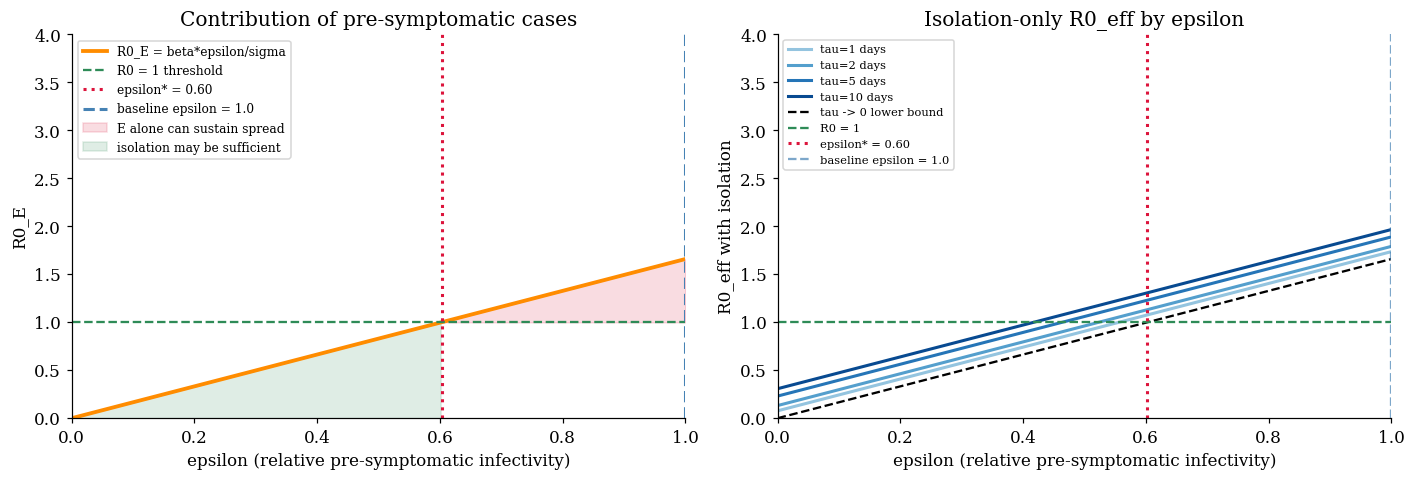

Saved figure: B2b_epsilon_star.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor='white')
eps_range = np.linspace(0, 1, 500)

# Panel 1: pre-symptomatic contribution.
ax = axes[0]
R0_E_curve = beta * eps_range / sigma
ax.plot(eps_range, R0_E_curve, 'darkorange', lw=2.5, label='R0_E = beta*epsilon/sigma')
ax.axhline(1.0, color='seagreen', ls='--', lw=1.5, label='R0 = 1 threshold')
ax.axvline(epsilon_star, color='crimson', ls=':', lw=2, label=f'epsilon* = {epsilon_star:.2f}')
ax.axvline(epsilon, color='steelblue', ls='--', lw=2, label=f'baseline epsilon = {epsilon}')
ax.fill_between(eps_range, R0_E_curve, 1, where=(R0_E_curve > 1), alpha=0.15, color='crimson', label='E alone can sustain spread')
ax.fill_between(eps_range, 0, np.minimum(R0_E_curve, 1), where=(eps_range <= epsilon_star), alpha=0.15, color='seagreen', label='isolation may be sufficient')
ax.set_xlabel('epsilon (relative pre-symptomatic infectivity)')
ax.set_ylabel('R0_E')
ax.set_title('Contribution of pre-symptomatic cases')
ax.legend(fontsize=8, loc='upper left')
ax.set_xlim(0, 1)
ax.set_ylim(0, 4)

# Panel 2: R0_eff under different tau values.
ax2 = axes[1]
tau_plot_vals = [1, 2, 5, 10]
colors_tau = cm.Blues(np.linspace(0.4, 0.9, len(tau_plot_vals)))
for tau_p, col in zip(tau_plot_vals, colors_tau):
    d = 1 / tau_p
    r0_eff_curve = beta * (eps_range / sigma + 1 / (gamma + d))
    ax2.plot(eps_range, r0_eff_curve, color=col, lw=2, label=f'tau={tau_p} days')
ax2.plot(eps_range, beta * eps_range / sigma, 'k--', lw=1.5, label='tau -> 0 lower bound')
ax2.axhline(1.0, color='seagreen', ls='--', lw=1.5, label='R0 = 1')
ax2.axvline(epsilon_star, color='crimson', ls=':', lw=2, label=f'epsilon* = {epsilon_star:.2f}')
ax2.axvline(epsilon, color='steelblue', ls='--', lw=1.5, alpha=0.7, label=f'baseline epsilon = {epsilon}')
ax2.set_xlabel('epsilon (relative pre-symptomatic infectivity)')
ax2.set_ylabel('R0_eff with isolation')
ax2.set_title('Isolation-only R0_eff by epsilon')
ax2.legend(fontsize=7.5, loc='upper left')
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 4)

plt.tight_layout()
plt.savefig('B2b_epsilon_star.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B2b_epsilon_star.png')

### Conclusion — the ε* threshold
Isolation could contain the epidemic only if pre-symptomatic infectivity were below ε* = σ/β ≈ 0.60. With the baseline ε = 1 > ε*, the pre-symptomatic reproduction number R0_E ≈ 1.66 > 1, so isolation alone fails for ANY ε above 0.60 — the conclusion does not depend on the exact value of ε.

## 1.3 Adding contact tracing (SEIQR)

Symptomatic isolation alone is not enough when $\epsilon > \epsilon^*$. Contact tracing targets exposed contacts before symptom onset and therefore reduces transmission from $E$.

**Parameters.**
- $\eta$: operational tracing efficiency, interpreted as the probability that an exposed contact is identified.
- $\psi$: compliance with quarantine after notification.
- $	au_{CT}$: delay, in days, from case detection/isolation to contact quarantine.

Here $\eta\psi$ is interpreted as the final probability that an exposed contact is successfully traced and complies with quarantine. This probability is discounted by the chance that tracing occurs before progression from exposed to infectious:

$$p_{trace}=\eta\psi,$$

$$p_{trace,eff}=p_{trace}\exp(-\sigma	au_{CT}),$$

$$	heta=\frac{\sigma p_{trace,eff}}{1-p_{trace,eff}}.$$

This makes contact tracing probabilistic, delayed, and constrained by disease progression.

### SEIQR + contact-tracing model structure

Compartments: $S, E, E_Q, I, Q, R$.

| Compartment | Description |
|---|---|
| S | Susceptible |
| E | Exposed/pre-symptomatic and potentially infectious |
| $E_Q$ | Exposed and traced/quarantined; assumed not to transmit |
| I | Symptomatic infectious |
| Q | Symptomatic isolated; assumed not to transmit |
| R | Removed/recovered |

The ODEs are

$$\frac{dS}{dt} = -\beta \frac{\epsilon E + I}{N} S,$$
$$\frac{dE}{dt} = \beta \frac{\epsilon E + I}{N} S - \sigma E - \theta E,$$
$$\frac{dE_Q}{dt} = \theta E - \sigma E_Q,$$
$$\frac{dI}{dt} = \sigma E - (\gamma + \delta) I,$$
$$\frac{dQ}{dt} = \delta I + \sigma E_Q - \gamma Q,$$
$$\frac{dR}{dt} = \gamma(I + Q).$$

The corresponding analytical effective reproduction number is

$$R_0^{CT} = \frac{\beta}{\sigma + \theta}\left(\epsilon + \frac{\sigma}{\gamma + \delta}\right).$$

Here $\theta$ is computed from the probability-to-hazard conversion defined above.

In [15]:
# Contact-tracing probability-to-hazard conversion.
def contact_tracing_rate(eta, psi, tau_CT, sigma):
    """
    Convert tracing efficiency and compliance into a tracing hazard.

    eta * psi is interpreted as the final probability that an exposed contact is
    identified and complies with quarantine. The term exp(-sigma * tau_CT)
    discounts this probability for operational delays, because some exposed
    contacts progress before tracing is completed.

    The returned theta satisfies theta / (sigma + theta) = p_trace_eff.
    """
    p_trace = np.clip(np.asarray(eta, dtype=float) * np.asarray(psi, dtype=float), 0.0, 0.999999)
    p_trace_eff = np.clip(p_trace * np.exp(-sigma * np.asarray(tau_CT, dtype=float)), 0.0, 0.999999)
    theta = sigma * p_trace_eff / (1.0 - p_trace_eff)
    return theta

eta_baseline = 0.70
psi_baseline = 0.70
tau_CT_baseline = 2
tau_iso = tau_baseline

delta_iso = 1 / tau_iso
theta_baseline = float(contact_tracing_rate(eta_baseline, psi_baseline, tau_CT_baseline, sigma))
p_trace_raw = eta_baseline * psi_baseline
p_trace_eff_baseline = p_trace_raw * np.exp(-sigma * tau_CT_baseline)

R0_CT_baseline = beta / (sigma + theta_baseline) * (epsilon + sigma / (gamma + delta_iso))
R0_iso_only_5 = beta * (epsilon / sigma + 1 / (gamma + delta_iso))

print('=' * 64)
print('  CONTACT TRACING PARAMETERS - SCENARIO 3')
print('=' * 64)
print(f'  eta (tracing efficiency)      = {eta_baseline}')
print(f'  psi (compliance)              = {psi_baseline}')
print(f'  tau_CT                        = {tau_CT_baseline} days')
print(f'  tau_iso                       = {tau_iso} days')
print()
print(f'  p_trace = eta*psi             = {p_trace_raw:.4f}')
print(f'  p_trace_eff                   = {p_trace_eff_baseline:.4f}')
print(f'  theta                 = {theta_baseline:.4f} day^-1')
print(f'  delta = 1/tau_iso             = {delta_iso:.4f} day^-1')
print()
print(f'  R0 baseline (S1)              = {R0_target:.4f}')
print(f'  R0_eff S2 (tau=5)             = {R0_iso_only_5:.4f}')
print(f'  R0_eff S3 (eta=psi=0.7)       = {R0_CT_baseline:.4f}')
print(f"  Containment?                  {'YES (R0 < 1)' if R0_CT_baseline < 1 else 'NO (R0 >= 1)'}")
print('=' * 64)


  CONTACT TRACING PARAMETERS - SCENARIO 3
  eta (tracing efficiency)      = 0.7
  psi (compliance)              = 0.7
  tau_CT                        = 2 days
  tau_iso                       = 5 days

  p_trace = eta*psi             = 0.4900
  p_trace_eff                   = 0.4385
  theta                 = 0.0434 day^-1
  delta = 1/tau_iso             = 0.2000 day^-1

  R0 baseline (S1)              = 2.1200
  R0_eff S2 (tau=5)             = 1.8896
  R0_eff S3 (eta=psi=0.7)       = 1.0610
  Containment?                  NO (R0 >= 1)


In [16]:
def seiqr_ct(t, y, beta, sigma, gamma, epsilon, delta, theta, N):
    """SEIQR model with contact tracing."""
    S, E, EQ, I, Q, R = y
    infection_force = beta * (epsilon * E + I) / N
    dS = -infection_force * S
    dE = infection_force * S - sigma * E - theta * E
    dEQ = theta * E - sigma * EQ
    dI = sigma * E - (gamma + delta) * I
    dQ = delta * I + sigma * EQ - gamma * Q
    dR = gamma * (I + Q)
    return [dS, dE, dEQ, dI, dQ, dR]


In [17]:
# Eta sweep using the probability-to-hazard tracing conversion.
eta_values = [0.0, 0.3, 0.5, 0.70, 0.85, 1.0]
results_s3 = {}
y0_s3_base = [N - 1, 0, 0, 1, 0, 0]

for eta in eta_values:
    theta = float(contact_tracing_rate(eta, psi_baseline, tau_CT_baseline, sigma))
    delta = delta_iso
    sol3 = solve_ivp(
        seiqr_ct, (0, T_days), y0_s3_base, t_eval=t_eval,
        args=(beta, sigma, gamma, epsilon, delta, theta, N),
        method='RK45', rtol=1e-8, atol=1e-10,
    )
    S3, E3, EQ3, I3, Q3, R3 = sol3.y
    R0_ct = beta / (sigma + theta) * (epsilon + sigma / (gamma + delta))
    p_trace = eta * psi_baseline
    p_trace_eff = p_trace * np.exp(-sigma * tau_CT_baseline)
    results_s3[eta] = {
        't': sol3.t, 'S': S3, 'E': E3, 'EQ': EQ3, 'I': I3, 'Q': Q3, 'R': R3,
        'R0_eff': R0_ct,
        'attack_rate': R3[-1] / N,
        'peak_I': I3.max(),
        'theta': theta,
        'p_trace': p_trace,
        'p_trace_eff': p_trace_eff,
    }

print(f"{'eta':>5} {'psi':>5} {'tau_CT':>8} {'p_eff':>9} {'theta':>9} {'R0_CT':>9} {'Attack%':>10} {'Peak I':>9}")
print('-' * 82)
for eta, r in sorted(results_s3.items()):
    contained = 'yes' if r['R0_eff'] < 1 else ''
    print(f"{eta:>5.2f} {psi_baseline:>5.2f} {tau_CT_baseline:>8} {r['p_trace_eff']:>9.4f} {r['theta']:>9.4f} {r['R0_eff']:>9.4f} {r['attack_rate']:>9.1%} {r['peak_I']:>9.0f} {contained}")
print()
print(f"Reference S1 (no intervention): attack rate = {R_sol[-1]/N:.1%}")
print(f"Reference S2 (isolation only, tau=5): attack rate = {results_s2[5]['attack_rate']:.1%}")


  eta   psi   tau_CT     p_eff     theta     R0_CT    Attack%    Peak I
----------------------------------------------------------------------------------
 0.00  0.70        2    0.0000    0.0000    1.8896     76.1%       183 
 0.30  0.70        2    0.1879    0.0129    1.5345     57.9%        94 
 0.50  0.70        2    0.3132    0.0253    1.2978     24.1%        39 
 0.70  0.70        2    0.4385    0.0434    1.0610      0.3%         1 
 0.85  0.70        2    0.5324    0.0633    0.8835      0.0%         1 yes
 1.00  0.70        2    0.6264    0.0931    0.7060      0.0%         1 yes

Reference S1 (no intervention): attack rate = 82.6%
Reference S2 (isolation only, tau=5): attack rate = 76.1%


In [18]:
# Critical eta* under the probability-to-hazard tracing model.
theta_star = beta * (epsilon + sigma / (gamma + delta_iso)) - sigma
if theta_star <= 0:
    p_eff_star = 0.0
else:
    p_eff_star = theta_star / (sigma + theta_star)

def critical_eta_for_threshold(psi, tau_CT, theta_star, sigma):
    """Critical eta required to achieve R0_CT <= 1 under the tracing model."""
    if theta_star <= 0:
        return 0.0
    p_eff_star = theta_star / (sigma + theta_star)
    denom = psi * np.exp(-sigma * tau_CT)
    return p_eff_star / denom if denom > 0 else np.inf

eta_star = critical_eta_for_threshold(psi_baseline, tau_CT_baseline, theta_star, sigma)

print('=' * 68)
print('  CRITICAL TRACING EFFICIENCY eta* - TRACING PARAMETERISATION')
print('=' * 68)
print(f'  theta*      = {theta_star:.4f} day^-1')
print(f'  p_eff*      = {p_eff_star:.4f}')
print(f'  eta*        = {eta_star:.3f} for psi={psi_baseline}, tau_CT={tau_CT_baseline} days')
print()
if eta_star <= 1:
    print(f'At least {eta_star:.0%} tracing efficiency is required under the baseline compliance and delay assumptions.')
else:
    print('Even eta=1 is insufficient under the baseline compliance and delay assumptions.')
print(f"With eta=0.70, R0_CT = {results_s3[0.70]['R0_eff']:.4f}.")
print('=' * 68)

print('\nSensitivity of eta* to tracing delay at fixed psi=0.70:')
print(f"{'tau_CT':>8} {'theta*':>10} {'p_eff*':>10} {'eta*':>8}")
print('-' * 43)
for tc in [1, 2, 3, 5]:
    eta_s = critical_eta_for_threshold(psi_baseline, tc, theta_star, sigma)
    print(f"{tc:>8} {theta_star:>10.4f} {p_eff_star:>10.4f} {min(eta_s, 1.0):>8.3f} {'unrealistic' if eta_s > 1 else ''}")


  CRITICAL TRACING EFFICIENCY eta* - TRACING PARAMETERISATION
  theta*      = 0.0494 day^-1
  p_eff*      = 0.4708
  eta*        = 0.752 for psi=0.7, tau_CT=2 days

At least 75% tracing efficiency is required under the baseline compliance and delay assumptions.
With eta=0.70, R0_CT = 1.0610.

Sensitivity of eta* to tracing delay at fixed psi=0.70:
  tau_CT     theta*     p_eff*     eta*
-------------------------------------------
       1     0.0494     0.4708    0.711 
       2     0.0494     0.4708    0.752 
       3     0.0494     0.4708    0.795 
       5     0.0494     0.4708    0.888 


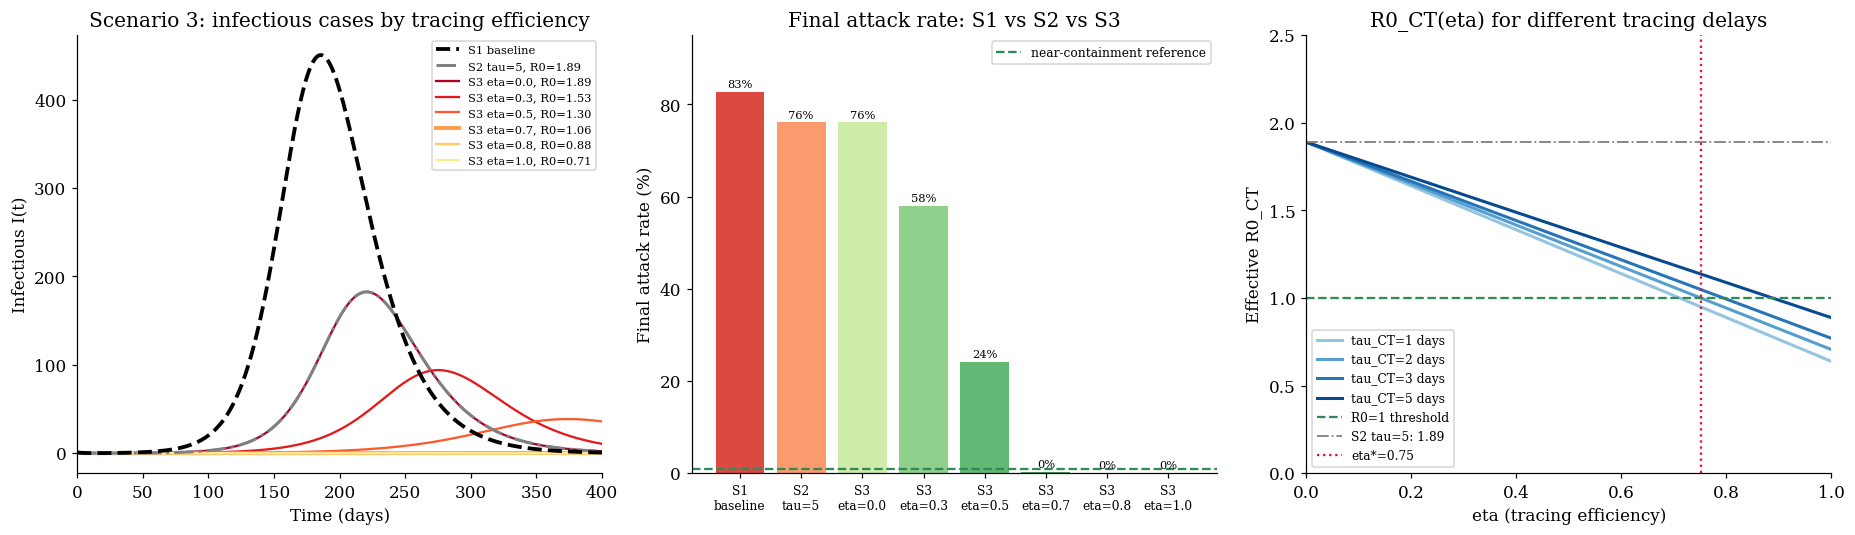

Saved figure: B3_SEIQR_CT.png


In [19]:
# Plot Scenario 3 using the tracing hazard and eta* threshold.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), facecolor='white')
colors_s3 = cm.YlOrRd_r(np.linspace(0.1, 0.85, len(eta_values)))

# Panel 1: I(t) by eta.
ax = axes[0]
ax.plot(t_sol, I_sol, 'k', lw=2.5, ls='--', label='S1 baseline', zorder=5)
ax.plot(results_s2[5]['t'], results_s2[5]['I'], 'gray', lw=2, ls='-.', label=f'S2 tau=5, R0={results_s2[5]["R0_eff"]:.2f}', zorder=4)
for (eta, res), col in zip(sorted(results_s3.items()), colors_s3):
    label = f'S3 eta={eta:.1f}, R0={res["R0_eff"]:.2f}'
    lw = 2.5 if abs(eta - eta_baseline) < 1e-9 else 1.5
    ax.plot(res['t'], res['I'], color=col, lw=lw, label=label)
ax.set_xlabel('Time (days)')
ax.set_ylabel('Infectious I(t)')
ax.set_title('Scenario 3: infectious cases by tracing efficiency')
ax.legend(fontsize=7.5)
ax.set_xlim(0, T_days)

# Panel 2: attack rate comparison.
ax2 = axes[1]
labels = ['S1\nbaseline', 'S2\ntau=5']
ars = [R_sol[-1] / N * 100, results_s2[5]['attack_rate'] * 100]
cols_bar = ['#d73027', '#fc8d59']
for eta in sorted(results_s3.keys()):
    labels.append(f'S3\neta={eta:.1f}')
    ars.append(results_s3[eta]['attack_rate'] * 100)
    cols_bar.append(cm.YlGn(0.3 + 0.6 * eta))
bars = ax2.bar(range(len(labels)), ars, color=cols_bar, alpha=0.88)
ax2.axhline(1.0, color='seagreen', ls='--', lw=1.5, label='near-containment reference')
ax2.set_xticks(range(len(labels)))
ax2.set_xticklabels(labels, fontsize=8)
ax2.set_ylabel('Final attack rate (%)')
ax2.set_title('Final attack rate: S1 vs S2 vs S3')
ax2.set_ylim(0, 95)
ax2.legend(fontsize=8)
for bar, val in zip(bars, ars):
    ax2.text(bar.get_x() + bar.get_width() / 2, val + 1, f'{val:.0f}%', ha='center', fontsize=7.5)

# Panel 3: R0_CT by eta and tau_CT.
ax3 = axes[2]
eta_range = np.linspace(0, 1, 300)
tau_ct_vals = [1, 2, 3, 5]
colors_tct = cm.Blues(np.linspace(0.4, 0.9, len(tau_ct_vals)))
for tc, col in zip(tau_ct_vals, colors_tct):
    theta_range = contact_tracing_rate(eta_range, psi_baseline, tc, sigma)
    r0_range = beta / (sigma + theta_range) * (epsilon + sigma / (gamma + delta_iso))
    ax3.plot(eta_range, r0_range, color=col, lw=2, label=f'tau_CT={tc} days')
ax3.axhline(1.0, color='seagreen', ls='--', lw=1.5, label='R0=1 threshold')
ax3.axhline(R0_iso_only_5, color='gray', ls='-.', lw=1.2, label=f'S2 tau=5: {R0_iso_only_5:.2f}')
if eta_star <= 1:
    ax3.axvline(eta_star, color='crimson', ls=':', lw=1.5, label=f'eta*={eta_star:.2f}')
else:
    ax3.text(0.52, 1.08, 'eta*>1 under baseline delay', color='crimson', fontsize=8)
ax3.set_xlabel('eta (tracing efficiency)')
ax3.set_ylabel('Effective R0_CT')
ax3.set_title('R0_CT(eta) for different tracing delays')
ax3.legend(fontsize=8)
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 2.5)

plt.tight_layout()
plt.savefig('B3_SEIQR_CT.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B3_SEIQR_CT.png')


### Conclusion — Contact tracing
Quarantining traced exposed contacts can suppress the outbreak: the success probability η·ψ (discounted by the delay e^(−σ·τ_CT)) is turned into a removal hazard, giving a critical efficiency η* ≈ 0.75. At the baseline η = ψ = 0.7 the system is only marginally controlled. This estimate is OPTIMISTIC because the ODE assumes random mixing; the network sections below relax that assumption.

## 1.4 Comparison of the three deterministic scenarios

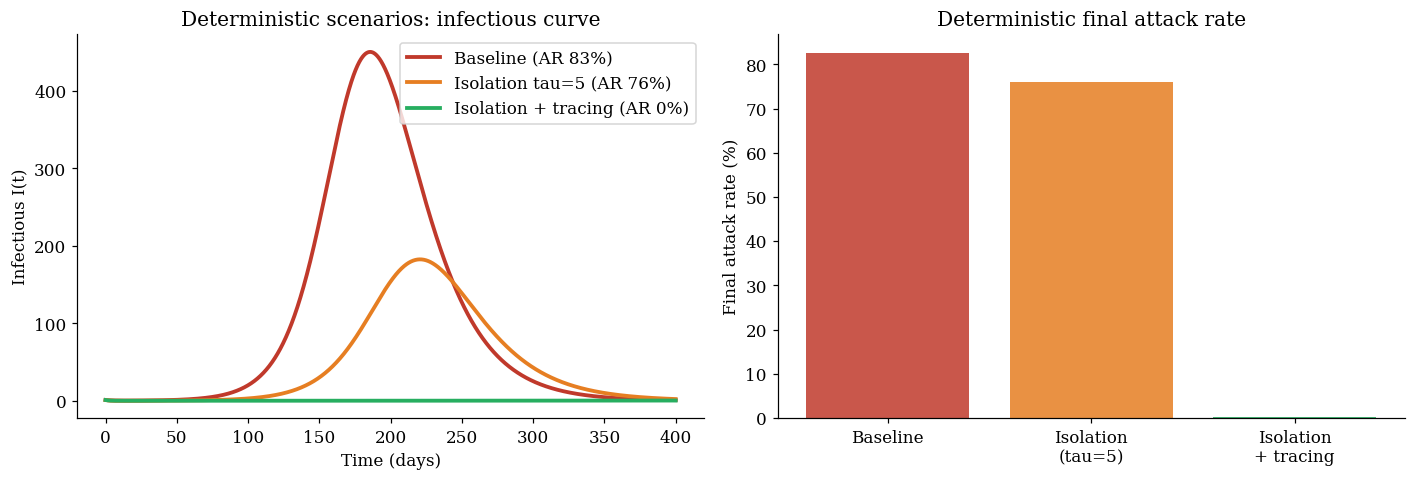

Deterministic attack rates -> baseline 83%, isolation 76%, isolation+tracing 0%


In [20]:
# Overlay the three deterministic scenarios at baseline intervention values.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor='white')
axes[0].plot(t_sol, I_sol, color='#c0392b', lw=2.5, label=f'Baseline (AR {attack_rate:.0%})')
axes[0].plot(results_s2[5]['t'], results_s2[5]['I'], color='#e67e22', lw=2.5,
             label=f"Isolation tau=5 (AR {results_s2[5]['attack_rate']:.0%})")
axes[0].plot(results_s3[0.70]['t'], results_s3[0.70]['I'], color='#27ae60', lw=2.5,
             label=f"Isolation + tracing (AR {results_s3[0.70]['attack_rate']:.0%})")
axes[0].set_xlabel('Time (days)'); axes[0].set_ylabel('Infectious I(t)')
axes[0].set_title('Deterministic scenarios: infectious curve'); axes[0].legend()
names = ['Baseline', 'Isolation\n(tau=5)', 'Isolation\n+ tracing']
ars = [attack_rate, results_s2[5]['attack_rate'], results_s3[0.70]['attack_rate']]
axes[1].bar(names, [a * 100 for a in ars], color=['#c0392b', '#e67e22', '#27ae60'], alpha=0.85)
axes[1].set_ylabel('Final attack rate (%)'); axes[1].set_title('Deterministic final attack rate')
plt.tight_layout(); plt.savefig('ODE_scenario_comparison.png', dpi=110); plt.show()
print('Deterministic attack rates -> baseline {:.0%}, isolation {:.0%}, isolation+tracing {:.0%}'.format(
      attack_rate, results_s2[5]['attack_rate'], results_s3[0.70]['attack_rate']))

### Conclusion — deterministic scenarios
Isolation only modestly lowers the final size; contact tracing is the only measure that, in this optimistic mean-field model, pushes the outbreak toward containment. But all of this assumes random mixing. The next parts ask: how much of this survives on a realistic contact network — which is the true setting for a close-contact pathogen like ANDV?

# 2. Global sensitivity analysis

**Why we do this.** Several model parameters are transferred from outbreaks observed in other settings and are therefore uncertain. A sensitivity analysis asks a simple question: *which of these uncertain inputs actually drive the results, and which barely matter?* This shows where the conclusions are fragile (and where better data would help), and confirms that the qualitative findings do not hinge on the exact value of any single parameter.

**Method.** This section uses a self-contained variance-based screening procedure:

1. Latin-hypercube samples are generated over the same parameter ranges.
2. The SEIQR+CT model is evaluated for each sample.
3. For each parameter, the first-order contribution is approximated as the variance of conditional bin means divided by total output variance.
4. A permutation score is added as a total-effect proxy: it measures how much output predictability is lost when a parameter is shuffled.

| Parameter | Range | Rationale |
|---|---:|---|
| $R_0$ | [1.24, 3.35] | Uncertainty around the pre-control outbreak estimate. |
| $\epsilon$ | [0.1, 1.0] | Plausible pre-symptomatic infectivity range, including a conservative baseline. |
| $\tau_{iso}$ | [1, 14] days | Operational isolation delay. |
| $\eta$ | [0, 1] | Tracing efficiency. |
| $\psi$ | [0.50, 1.0] | Quarantine compliance. |
| $\tau_{CT}$ | [1, 5] days | Tracing delay. |

In [21]:
# Fixed parameters for the sensitivity block ----------------------------------
sigma_f = 1 / 18
gamma_f = 1 / 5
N_pop = 10_000
T_sim = 400
N_TEVAL = 180

problem = {
    'num_vars': 6,
    'names': ['R0', 'epsilon', 'tau_iso', 'eta', 'psi', 'tau_CT'],
    'bounds': np.array([
        [1.24, 3.35],
        [0.10, 1.00],
        [1.0, 14.0],
        [0.0, 1.0],
        [0.50, 1.0],
        [1.0, 5.0],
    ], dtype=float),
}

N_SENS = 384  # self-contained runtime-friendly sample size.
rng_sens = np.random.default_rng(12345)

# Latin-hypercube sampling in [0, 1]^d, then scale to bounds.
d = problem['num_vars']
U = np.zeros((N_SENS, d))
for j in range(d):
    perm = rng_sens.permutation(N_SENS)
    U[:, j] = (perm + rng_sens.random(N_SENS)) / N_SENS
bounds = problem['bounds']
param_values = bounds[:, 0] + U * (bounds[:, 1] - bounds[:, 0])

print(f"Parameters:          {problem['num_vars']}")
print(f"Samples:             {len(param_values)}")
print("Method:              Latin-hypercube + variance-based screening")


Parameters:          6
Samples:             384
Method:              Latin-hypercube + variance-based screening


In [22]:
# Sensitivity evaluation uses the contact_tracing_rate() function.
def eval_model(params):
    """Evaluate the SEIQR+CT ODE for one parameter vector."""
    R0, eps, tau_iso_i, eta_i, psi_i, tau_CT_i = params
    beta_i = R0 / (eps / sigma_f + 1 / gamma_f)
    delta_i = 1.0 / tau_iso_i
    theta_i = float(contact_tracing_rate(eta_i, psi_i, tau_CT_i, sigma_f))
    R0_ct_i = beta_i / (sigma_f + theta_i) * (eps + sigma_f / (gamma_f + delta_i))

    def rhs(t, y):
        S, E, EQ, I, Q, R = y
        infection_force = beta_i * (eps * E + I) / N_pop
        return [
            -infection_force * S,
            infection_force * S - (sigma_f + theta_i) * E,
            theta_i * E - sigma_f * EQ,
            sigma_f * E - (gamma_f + delta_i) * I,
            delta_i * I + sigma_f * EQ - gamma_f * Q,
            gamma_f * (I + Q),
        ]

    sol_i = solve_ivp(
        rhs, (0, T_sim), [N_pop - 1, 0, 0, 1, 0, 0],
        t_eval=np.linspace(0, T_sim, N_TEVAL),
        method='RK45', rtol=1e-6, atol=1e-8,
    )
    I_i = sol_i.y[3]
    R_i = sol_i.y[5]
    return R_i[-1] / N_pop, I_i.max() / N_pop, R0_ct_i

Y_ar = np.zeros(N_SENS)
Y_peak = np.zeros(N_SENS)
Y_r0ct = np.zeros(N_SENS)

t_start = time.time()
for i, p in enumerate(param_values):
    Y_ar[i], Y_peak[i], Y_r0ct[i] = eval_model(p)
    if (i + 1) % 200 == 0:
        elapsed = time.time() - t_start
        rate = (i + 1) / elapsed
        eta_sec = (N_SENS - i - 1) / rate
        print(f"  {i+1:>4}/{N_SENS} ({(i+1)/N_SENS:.0%}) - {elapsed:.0f}s elapsed - about {eta_sec:.0f}s remaining")

elapsed = time.time() - t_start
print(f"\nCompleted: {N_SENS} ODE evaluations in {elapsed:.1f}s")
for name, Y in [('Final attack rate', Y_ar), ('Peak I/N', Y_peak), ('Analytical R0_CT', Y_r0ct)]:
    print(f"  {name:<22} min={Y.min():.3f} median={np.median(Y):.3f} max={Y.max():.3f} std={Y.std():.3f}")


   200/384 (52%) - 1s elapsed - about 1s remaining

Completed: 384 ODE evaluations in 1.6s
  Final attack rate      min=0.000 median=0.119 max=0.928 std=0.333
  Peak I/N               min=0.000 median=0.002 max=0.049 std=0.011
  Analytical R0_CT       min=0.151 median=1.243 max=2.834 std=0.524


In [23]:
def binned_first_order(X, Y, n_bins=12):
    """Approximate first-order variance contribution Var(E[Y|X_j])/Var(Y)."""
    total_var = np.var(Y)
    if total_var <= 0:
        return np.zeros(X.shape[1])
    scores = []
    for j in range(X.shape[1]):
        q = np.quantile(X[:, j], np.linspace(0, 1, n_bins + 1))
        q[0] -= 1e-12
        q[-1] += 1e-12
        bin_ids = np.digitize(X[:, j], q[1:-1])
        means = np.array([Y[bin_ids == b].mean() if np.any(bin_ids == b) else np.nan for b in range(n_bins)])
        counts = np.array([np.sum(bin_ids == b) for b in range(n_bins)], dtype=float)
        valid = counts > 0
        cond_var = np.average((means[valid] - Y.mean()) ** 2, weights=counts[valid])
        scores.append(cond_var / total_var)
    return np.array(scores)

# Total-effect proxy: reduction in nearest-bin prediction quality when one variable is permuted.
def permutation_total_proxy(X, Y, n_bins=10, seed=777):
    rng = np.random.default_rng(seed)
    base = binned_first_order(X, Y, n_bins=n_bins)
    proxy = []
    for j in range(X.shape[1]):
        Xp = X.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        perm_score = binned_first_order(Xp, Y, n_bins=n_bins)[j]
        proxy.append(max(base[j], base[j] - perm_score))
    return np.array(proxy)

param_labels = ['R0', 'epsilon', 'tau_iso', 'eta', 'psi', 'tau_CT']

def make_sensitivity_result(Y):
    S1 = binned_first_order(param_values, Y, n_bins=12)
    ST = np.maximum(S1, permutation_total_proxy(param_values, Y, n_bins=10))
    return {'S1': np.clip(S1, 0, 1), 'ST': np.clip(ST, 0, 1)}

sens_results = {
    'AR': make_sensitivity_result(Y_ar),
    'Peak': make_sensitivity_result(Y_peak),
    'R0CT': make_sensitivity_result(Y_r0ct),
}

for label, key in [('Final attack rate', 'AR'), ('Peak prevalence', 'Peak'), ('Analytical R0_CT', 'R0CT')]:
    res = sens_results[key]
    print(f"\n{'='*60}\nOutput: {label}")
    print(f"{'Parameter':<12} {'S1 approx':>10} {'Total proxy':>13}")
    print('-' * 38)
    for p, s1, st in zip(param_labels, res['S1'], res['ST']):
        bar = '█' * int(st * 20)
        print(f"{p:<12} {s1:>10.3f} {st:>13.3f}  {bar}")
print('\nSensitivity results saved in sens_results.')



Output: Final attack rate
Parameter     S1 approx   Total proxy
--------------------------------------
R0                0.434         0.434  ████████
epsilon           0.046         0.048  
tau_iso           0.053         0.053  █
eta               0.221         0.229  ████
psi               0.078         0.078  █
tau_CT            0.037         0.046  

Output: Peak prevalence
Parameter     S1 approx   Total proxy
--------------------------------------
R0                0.286         0.286  █████
epsilon           0.049         0.055  █
tau_iso           0.116         0.116  ██
eta               0.239         0.247  ████
psi               0.059         0.059  █
tau_CT            0.030         0.040  

Output: Analytical R0_CT
Parameter     S1 approx   Total proxy
--------------------------------------
R0                0.358         0.358  ███████
epsilon           0.052         0.056  █
tau_iso           0.044         0.044  
eta               0.384         0.390  ███████
psi      

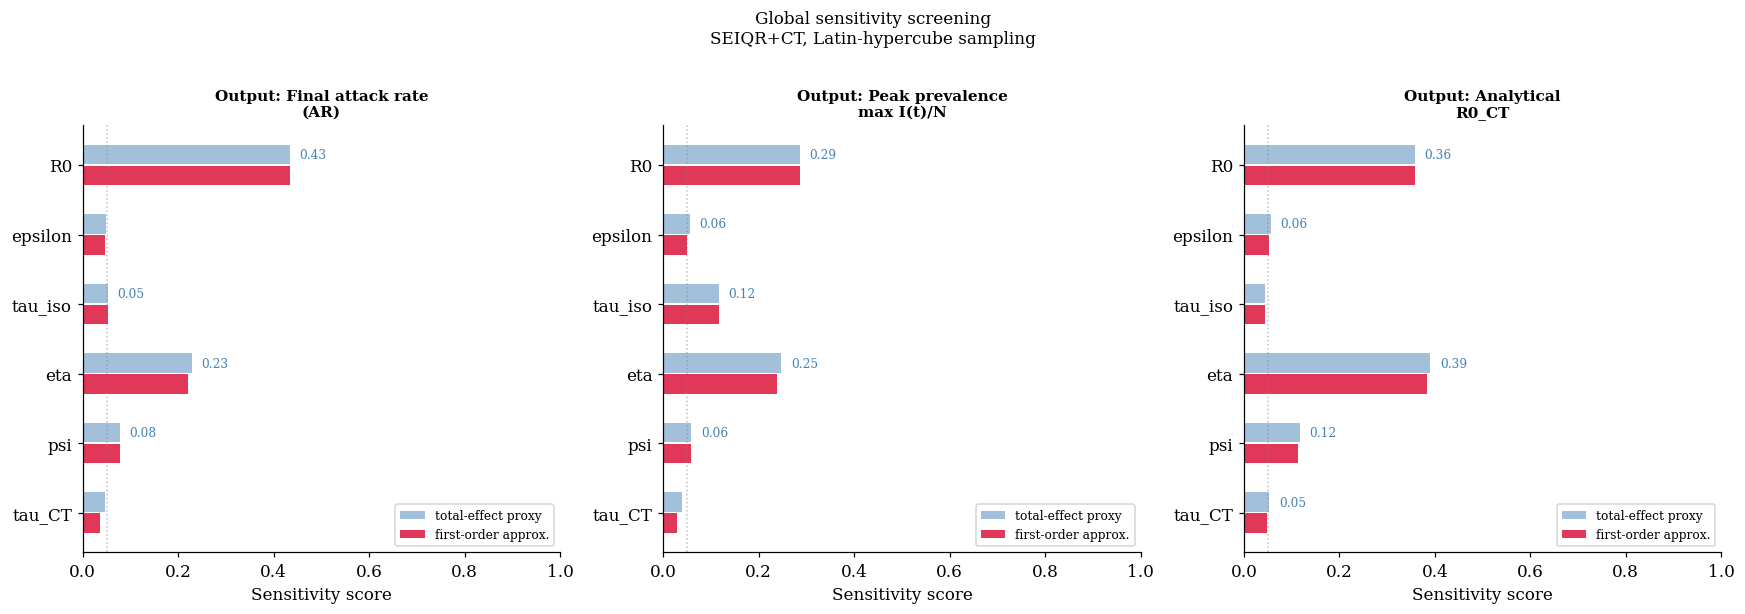

Saved figure: B4_Sensitivity_indices.png


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), facecolor='white')
output_labels = ['Final attack rate\n(AR)', 'Peak prevalence\nmax I(t)/N', 'Analytical\nR0_CT']
output_keys = ['AR', 'Peak', 'R0CT']
y_pos = np.arange(len(param_labels))

for ax, key, title in zip(axes, output_keys, output_labels):
    res = sens_results[key]
    S1 = np.clip(res['S1'], 0, None)
    ST = np.clip(res['ST'], 0, None)
    ax.barh(y_pos - 0.15, ST, height=0.28, color='steelblue', alpha=0.5, label='total-effect proxy')
    ax.barh(y_pos + 0.15, S1, height=0.28, color='crimson', alpha=0.85, label='first-order approx.')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(param_labels)
    ax.set_xlabel('Sensitivity score')
    ax.set_title(f'Output: {title}', fontsize=10, fontweight='bold')
    ax.set_xlim(0, max(1.0, ST.max() * 1.2))
    ax.axvline(0.05, color='gray', ls=':', lw=1, alpha=0.5)
    ax.legend(fontsize=8, loc='lower right')
    ax.invert_yaxis()
    for j in range(len(param_labels)):
        if ST[j] > 0.05:
            ax.text(ST[j] + 0.02, y_pos[j] - 0.15, f'{ST[j]:.2f}', va='center', fontsize=8, color='steelblue')

plt.suptitle('Global sensitivity screening\nSEIQR+CT, Latin-hypercube sampling', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig('B4_Sensitivity_indices.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B4_Sensitivity_indices.png')


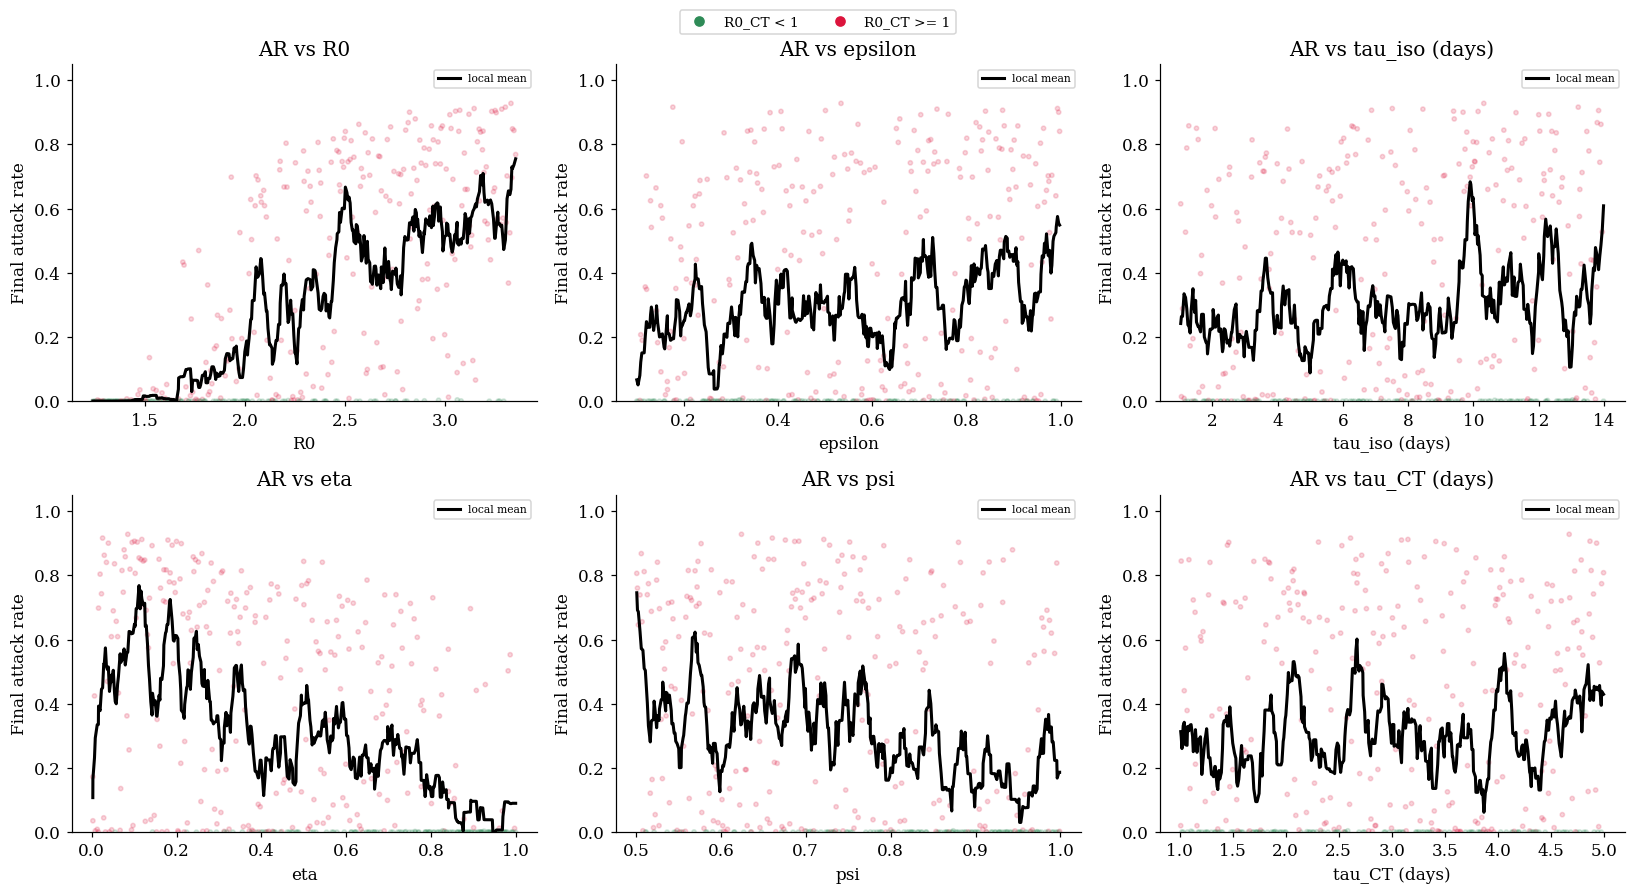

Saved figure: B4b_scatter.png


In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor='white')
param_idx = {'R0': 0, 'epsilon': 1, 'tau_iso': 2, 'eta': 3, 'psi': 4, 'tau_CT': 5}
param_names_plot = ['R0', 'epsilon', 'tau_iso (days)', 'eta', 'psi', 'tau_CT (days)']

for ax, (pname, pidx) in zip(axes.flat, param_idx.items()):
    x = param_values[:, pidx]
    y = Y_ar
    colors = np.where(Y_r0ct < 1, 'seagreen', 'crimson')
    ax.scatter(x, y, c=colors, alpha=0.18, s=8, rasterized=True)
    sort_idx = np.argsort(x)
    y_smooth = uniform_filter1d(y[sort_idx], size=max(5, len(x) // 30))
    ax.plot(x[sort_idx], y_smooth, 'k', lw=2, label='local mean')
    ax.set_xlabel(param_names_plot[pidx])
    ax.set_ylabel('Final attack rate')
    ax.set_title(f'AR vs {param_names_plot[pidx]}')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='seagreen', markersize=8, label='R0_CT < 1'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='crimson', markersize=8, label='R0_CT >= 1'),
]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=9, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.savefig('B4b_scatter.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B4b_scatter.png')


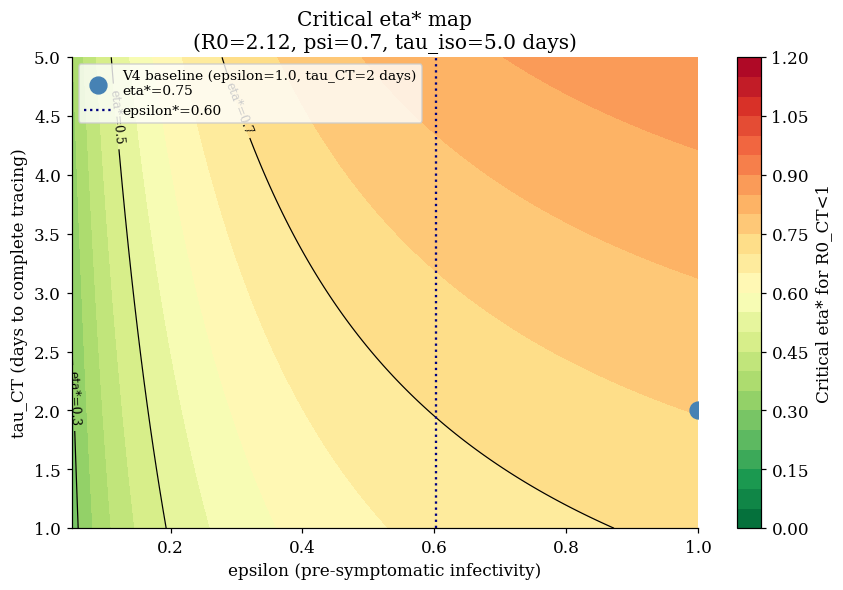

Saved figure: B4c_eta_star_map.png
Red areas with eta*>1 indicate parameter combinations where tracing alone is insufficient; beta must also be reduced.


In [26]:
# Critical eta* map for the probability-to-hazard tracing model.
R0_f = 2.12
psi_f = 0.70
tau_iso_f = 5.0
delta_f = 1 / tau_iso_f

eps_grid = np.linspace(0.05, 1.00, 200)
tauCT_grid = np.linspace(1, 5, 200)
EPS, TCT = np.meshgrid(eps_grid, tauCT_grid)
BETA = R0_f / (EPS / sigma_f + 1 / gamma_f)
THETA_STAR = BETA * (EPS + sigma_f / (gamma_f + delta_f)) - sigma_f
P_EFF_STAR = np.where(THETA_STAR > 0, THETA_STAR / (sigma_f + THETA_STAR), 0.0)
DENOM = psi_f * np.exp(-sigma_f * TCT)
ETA_STAR = np.where(DENOM > 0, P_EFF_STAR / DENOM, np.inf)
ETA_STAR = np.clip(ETA_STAR, 0, 1.5)

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor='white')
cf = ax.contourf(eps_grid, tauCT_grid, ETA_STAR, levels=np.linspace(0, 1.2, 25), cmap='RdYlGn_r')
cs = ax.contour(eps_grid, tauCT_grid, ETA_STAR, levels=[0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0], colors='black', linewidths=0.8)
ax.clabel(cs, fmt='eta*=%.1f', fontsize=8)
ax.contour(eps_grid, tauCT_grid, ETA_STAR, levels=[1.0], colors=['crimson'], linewidths=2, linestyles='--')
base_tau_idx = np.argmin(abs(tauCT_grid - tau_CT_baseline))
base_eps_idx = np.argmin(abs(eps_grid - epsilon))
base_eta_star = ETA_STAR[base_tau_idx, base_eps_idx]
ax.scatter([epsilon], [tau_CT_baseline], color='steelblue', s=120, zorder=5,
           label=f'V4 baseline (epsilon={epsilon:.1f}, tau_CT={tau_CT_baseline} days)\neta*={base_eta_star:.2f}')
ax.axvline(epsilon_star, color='navy', ls=':', lw=1.5, label=f'epsilon*={epsilon_star:.2f}')
plt.colorbar(cf, ax=ax, label='Critical eta* for R0_CT<1')
ax.set_xlabel('epsilon (pre-symptomatic infectivity)')
ax.set_ylabel('tau_CT (days to complete tracing)')
ax.set_title(f'Critical eta* map\n(R0={R0_f}, psi={psi_f}, tau_iso={tau_iso_f} days)')
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('B4c_eta_star_map.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B4c_eta_star_map.png')
print('Red areas with eta*>1 indicate parameter combinations where tracing alone is insufficient; beta must also be reduced.')


### Conclusion — Sensitivity
The screening shows which uncertain inputs drive the outcome (chiefly tracing efficiency and R0); σ and γ are fixed to focus on policy-relevant parameters, and β is recalibrated per sample so R0 is the uncertainty axis. The first-order scores are a screening measure. Takeaway: the qualitative conclusions are robust to plausible parameter uncertainty.

# 3. Contact-network model

ANDV transmission is primarily associated with close and prolonged interpersonal exposure. While compartmental models provide a useful population-level approximation, they do not explicitly represent the heterogeneous contact patterns through which transmission occurs. The contact network model addresses this limitation by incorporating key structural features of human interactions:

1. Household clustering. Individuals belonging to the same household are represented as densely connected groups, reflecting the prolonged and repeated contacts that occur in shared living environments.
2. Stable extra-household contacts. Additional links represent recurrent social interactions between individuals from different households, such as friendships, workplace contacts, and regular community encounters.

The resulting network combines household cliques with a structured extra-household contact layer, providing a realistic representation of close-contact transmission pathways while remaining computationally tractable. This framework captures the clustering and repeated-contact patterns that are considered important for person-to-person transmission of Andes virus.

## 3.1 Building the network: structure, calibration and an outbreak snapshot

In [27]:
N = 10_000
SEED_NET = 42

# Household-size distribution, Italy (ISTAT 2021 permanent census).
HH_SIZES = np.array([1, 2, 3, 4, 5])
HH_PROBS = np.array([0.330, 0.279, 0.187, 0.146, 0.058])

# Five broad age groups and their Italian population shares (ISTAT 2021).
AGE_LABELS = np.array(['0-4', '5-17', '18-39', '40-64', '65+'])
AGE_PROBS = np.array([0.040, 0.125, 0.245, 0.360, 0.230]); AGE_PROBS = AGE_PROBS / AGE_PROBS.sum()

# Age-by-age contact matrix for Italy from the Prem et al. (2021) synthetic contact
# matrices (16 age bands, all settings), aggregated to the five groups above
# (15-19 band split 3/5 - 2/5 across 5-17 / 18-39; 75+ folded into 65+).
# Role: it weights ONLY *which* age an extra-household contact is with (age-assortative
# mixing, an enrichment of the plain Poisson layer). It does not affect the disease, which
# is age-homogeneous for ANDV (Martinez et al. 2020). The *number* of close contacts
# (degree ~4) comes from the physical/prolonged subset of POLYMOD (Mossong 2008; Melegaro 2011).
CONTACT_MATRIX = np.array([
    [7.4790, 3.1441, 4.2472, 4.6766, 1.2430],
    [0.5940, 13.9728, 5.2909, 4.5148, 0.8631],
    [0.7231, 2.7034, 11.2264, 6.2468, 1.0240],
    [0.5038, 2.6619, 5.7520, 8.4265, 1.6285],
    [0.2196, 0.6672, 2.3000, 4.8162, 3.3120],
], dtype=float)
CONTACT_PROBS = CONTACT_MATRIX / CONTACT_MATRIX.sum(axis=1, keepdims=True)

EXTRA_HOUSEHOLD_DEGREE_TARGET = 4.0   # mean close extra-household contacts (POLYMOD physical/prolonged subset)


def build_close_contact_network(N, seed=SEED_NET, extra_degree_target=EXTRA_HOUSEHOLD_DEGREE_TARGET,
                                overdispersion=None):
    """Two-layer ANDV close-contact network.

    Layer 1 (household): complete cliques, sizes drawn from the ISTAT distribution.
    Layer 2 (extra-household): a sparse layer whose *degree* is set by contact intensity
        (Poisson with mean extra_degree_target; gamma-Poisson if overdispersion is given),
        enriched with age-assortative partner choice from the Prem (2021) contact matrix.
    Returns (G, age_group, hh_id).
    """
    rng = np.random.default_rng(seed)
    G = nx.Graph(); G.add_nodes_from(range(N))
    age_group = rng.choice(len(AGE_LABELS), size=N, p=AGE_PROBS)
    hh_id = np.empty(N, dtype=np.int32)

    node = 0; household = 0
    while node < N:
        size = min(int(rng.choice(HH_SIZES, p=HH_PROBS)), N - node)
        members = list(range(node, node + size))
        for i in range(len(members)):
            for j in range(i + 1, len(members)):
                G.add_edge(members[i], members[j], layer='household')
        hh_id[node:node + size] = household
        node += size; household += 1

    nodes_by_age = [np.where(age_group == g)[0] for g in range(len(AGE_LABELS))]
    mean_attempts = extra_degree_target / 2.0
    if overdispersion is None:
        extra_attempts = rng.poisson(mean_attempts, size=N)
    else:
        k = max(float(overdispersion), 1e-6)
        rates = rng.gamma(shape=k, scale=mean_attempts / k, size=N)
        extra_attempts = rng.poisson(rates)

    for u, n_contacts in enumerate(extra_attempts):
        ego_age = age_group[u]
        for _ in range(int(n_contacts)):
            target_age = rng.choice(len(AGE_LABELS), p=CONTACT_PROBS[ego_age])
            candidates = nodes_by_age[target_age]
            if candidates.size == 0:
                continue
            for _attempt in range(15):
                v = int(rng.choice(candidates))
                if v != u and hh_id[v] != hh_id[u]:
                    if not G.has_edge(u, v):
                        G.add_edge(u, v, layer='extra_close')
                    break

    return G, age_group, hh_id


G, age_group, hh_id = build_close_contact_network(N, seed=SEED_NET)
adj = nx.to_scipy_sparse_array(G, format='csr', dtype=np.float64)
A = adj
indptr, indices = A.indptr, A.indices

degrees = np.diff(A.indptr)
hh_deg = np.zeros(N, dtype=int); extra_deg = np.zeros(N, dtype=int)
for u, v, data in G.edges(data=True):
    if data.get('layer') == 'household':
        hh_deg[u] += 1; hh_deg[v] += 1
    else:
        extra_deg[u] += 1; extra_deg[v] += 1

sample_nodes = np.random.default_rng(0).choice(N, 1500, replace=False)
C_mean = np.mean(list(nx.clustering(G, nodes=sample_nodes.tolist()).values()))

print(f'Nodes: {N}   Edges: {G.number_of_edges()}')
print(f'Mean degree <k> = {degrees.mean():.2f}')
print(f'  household mean degree          = {hh_deg.mean():.2f}')
print(f'  extra-household mean degree    = {extra_deg.mean():.2f}')
print(f'Mean clustering C = {C_mean:.3f}')
print('Extra-household degree from contact intensity (POLYMOD); partners age-assortative (Prem 2021 matrix).')


Nodes: 10000   Edges: 29987
Mean degree <k> = 6.00
  household mean degree          = 1.96
  extra-household mean degree    = 4.03
Mean clustering C = 0.119
Extra-household degree from contact intensity (POLYMOD); partners age-assortative (Prem 2021 matrix).


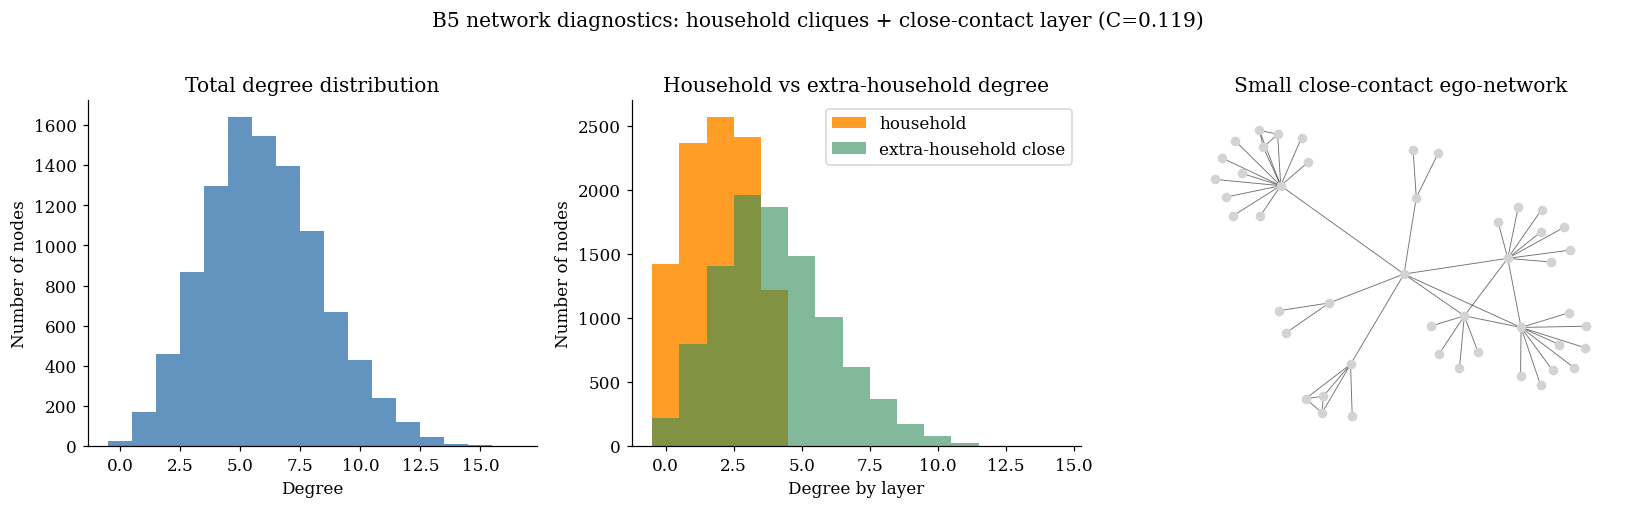

Saved figure: B5_network_analysis.png


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), facecolor='white')

axes[0].hist(degrees, bins=np.arange(degrees.min(), degrees.max() + 2) - 0.5, color='steelblue', alpha=0.85)
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Number of nodes')
axes[0].set_title('Total degree distribution')

axes[1].hist(hh_deg, bins=np.arange(hh_deg.min(), hh_deg.max() + 2) - 0.5, color='darkorange', alpha=0.85, label='household')
axes[1].hist(extra_deg, bins=np.arange(extra_deg.min(), extra_deg.max() + 2) - 0.5, color='seagreen', alpha=0.60, label='extra-household close')
axes[1].set_xlabel('Degree by layer')
axes[1].set_ylabel('Number of nodes')
axes[1].set_title('Household vs extra-household degree')
axes[1].legend()

# Draw a small connected ego-network sample for visual intuition.
rng_plot = np.random.default_rng(3)
center = int(rng_plot.integers(N))
sub_nodes = {center}
frontier = {center}
for _ in range(2):
    new_frontier = set()
    for node in frontier:
        new_frontier.update(G.neighbors(node))
    sub_nodes.update(new_frontier)
    frontier = new_frontier
    if len(sub_nodes) > 120:
        break
sub_nodes = list(sub_nodes)[:120]
H = G.subgraph(sub_nodes).copy()
pos = nx.spring_layout(H, seed=4)
nx.draw_networkx_nodes(H, pos, node_size=28, node_color='lightgray', ax=axes[2])
nx.draw_networkx_edges(H, pos, width=0.6, alpha=0.55, ax=axes[2])
axes[2].set_title('Small close-contact ego-network')
axes[2].axis('off')

plt.suptitle(f'B5 network diagnostics: household cliques + close-contact layer (C={C_mean:.3f})', y=1.02)
plt.tight_layout()
plt.savefig('B5_network_analysis.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B5_network_analysis.png')


### Network visualization (sample subgraph)

The previous diagnostics summarize the degree structure of the single close-contact graph.  
This additional plot visualizes a small connected sample of the same network and makes the two edge types explicit:

- orange edges: household clique contacts;
- blue dashed edges: extra-household close/prolonged contacts.

The full graph has 10,000 nodes, so the plot uses a reproducible local sample rather than drawing the entire network.

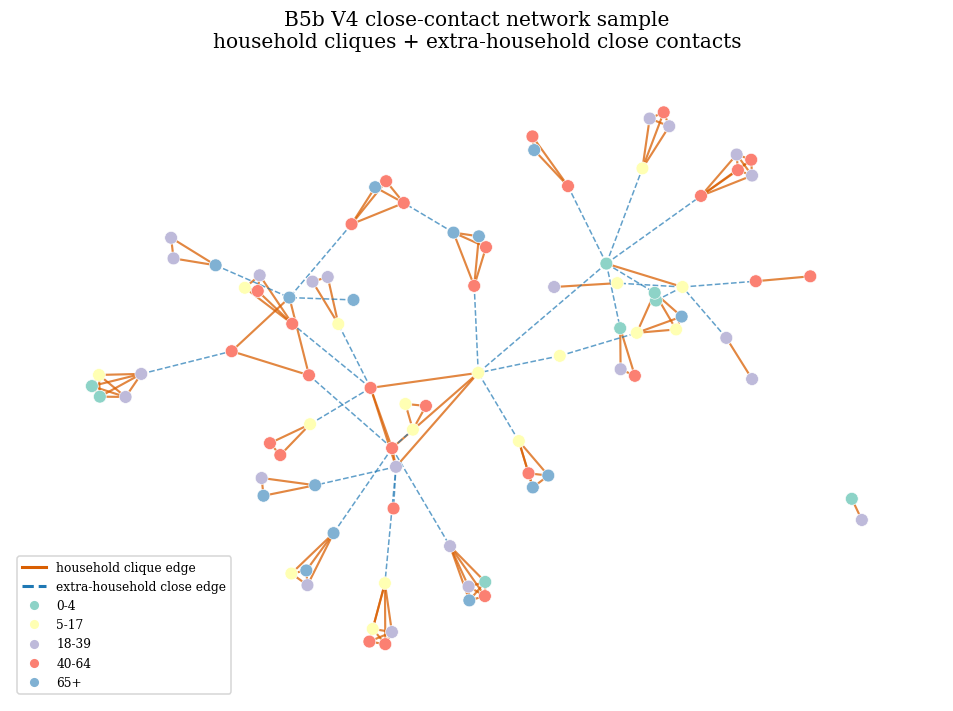

Visual sample nodes: 90
Visual sample edges: 146
  household clique edges: 117
  extra-household close edges: 29
Saved figure: B5b_explicit_close_contact_network_plot.png


In [29]:


from matplotlib.lines import Line2D

rng_visual = np.random.default_rng(44)

candidate_nodes = np.where(extra_deg >= 3)[0]
visual_center = int(rng_visual.choice(candidate_nodes if candidate_nodes.size else np.arange(N)))
center_household = hh_id[visual_center]

visual_nodes = set(np.where(hh_id == center_household)[0].tolist())


for u in list(visual_nodes):
    for v in G.neighbors(u):
        if G[u][v].get('layer') == 'extra_close':
            visual_nodes.update(np.where(hh_id == hh_id[v])[0].tolist())

for u in list(visual_nodes):
    for v in G.neighbors(u):
        if G[u][v].get('layer') == 'extra_close' and len(visual_nodes) < 90:
            visual_nodes.update(np.where(hh_id == hh_id[v])[0].tolist())

visual_nodes = sorted(list(visual_nodes))[:90]
H_vis = G.subgraph(visual_nodes).copy()


pos_vis = nx.spring_layout(H_vis, seed=44, k=0.35, iterations=120)

household_edges = [(u, v) for u, v, d in H_vis.edges(data=True) if d.get('layer') == 'household']
extra_edges = [(u, v) for u, v, d in H_vis.edges(data=True) if d.get('layer') == 'extra_close']

age_palette = ['#8dd3c7', '#ffffb3', '#bebada', '#fb8072', '#80b1d3']
node_colours = [age_palette[int(age_group[n]) % len(age_palette)] for n in H_vis.nodes()]

fig, ax = plt.subplots(figsize=(8.8, 6.6), facecolor='white')

nx.draw_networkx_edges(
    H_vis, pos_vis, edgelist=household_edges,
    width=1.4, alpha=0.75, edge_color='#d95f02', ax=ax,
)
nx.draw_networkx_edges(
    H_vis, pos_vis, edgelist=extra_edges,
    width=1.0, alpha=0.70, edge_color='#1f78b4', style='dashed', ax=ax,
)
nx.draw_networkx_nodes(
    H_vis, pos_vis, node_size=70, node_color=node_colours,
    linewidths=0.4, edgecolors='white', ax=ax,
)

ax.set_title('B5b V4 close-contact network sample\nhousehold cliques + extra-household close contacts')
ax.axis('off')

edge_legend = [
    Line2D([0], [0], color='#d95f02', lw=2, label='household clique edge'),
    Line2D([0], [0], color='#1f78b4', lw=2, linestyle='--', label='extra-household close edge'),
]
age_legend = [Line2D([0], [0], marker='o', color='w', label=lab, markerfacecolor=age_palette[i], markersize=7) for i, lab in enumerate(AGE_LABELS)]
ax.legend(handles=edge_legend + age_legend, loc='lower left', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig('B5b_explicit_close_contact_network_plot.png', dpi=120)
plt.show()
plt.close(fig)

print(f'Visual sample nodes: {H_vis.number_of_nodes()}')
print(f'Visual sample edges: {H_vis.number_of_edges()}')
print(f'  household clique edges: {len(household_edges)}')
print(f'  extra-household close edges: {len(extra_edges)}')
print('Saved figure: B5b_explicit_close_contact_network_plot.png')


### Conclusion — Contact network
The two-layer network is the realistic contact structure: household cliques (ISTAT sizes) plus a sparse extra-household layer whose degree (~4) reflects close-contact intensity (POLYMOD physical/prolonged contacts) and whose partners are age-assortative (Prem 2021 matrix). The resulting clustering and degree distribution are exactly what the homogeneous ODE cannot capture; this network is the substrate for the stochastic simulation that follows.

### Calibrating the per-contact transmission probability

A naive mean-field formula $p_I=\beta/\langle k\rangle$ assumes independent contacts and homogeneous mixing. In a clustered network, many potential transmission paths are redundant because household and social neighbors overlap. Therefore, a per-contact transmission probability calibrated only by mean degree underestimates the probability needed to reproduce the early exponential growth rate.

The early exponential growth rate for the linearized SEIR system is obtained from

$$r^2 + r(\sigma + \gamma - \beta\epsilon) - \sigma\gamma(R_0 - 1) = 0.$$

The calibrated transmission probability is then chosen so that stochastic network simulations reproduce the target growth dynamics implied by the epidemiological parameters. This approach ensures consistency between the contact-network representation and the reproduction number used throughout the study.

The calibrated value is subsequently employed in the stochastic simulations, while additional heterogeneity is incorporated through the age-structured contact network and Monte Carlo framework described in the following sections.

In [30]:

R0 = R0_target
SIGMA = sigma
GAMMA = gamma
EPS = epsilon
BETA = beta
TAU_ISO = tau_baseline
DELTA = 1 / TAU_ISO
ETA = eta_baseline
PSI = psi_baseline
TAU_CT = tau_CT_baseline

# ODE early growth rate.
J = np.array([[BETA * EPS - SIGMA, BETA], [SIGMA, -GAMMA]])
r_star = max(np.linalg.eigvals(J).real)

p_EI = 1 - np.exp(-SIGMA)
p_rec_I = 1 - np.exp(-GAMMA)
p_rec_Q = p_rec_I
p_I_naive = BETA / degrees.mean()


def early_growth_rate_on_network(A_matrix, p_I, n_runs=24, seed_base=61000, horizon=70):
    """Estimate early incidence growth on a fixed graph for a candidate per-edge probability."""
    n_nodes = A_matrix.shape[0]
    slopes = []
    for run in range(n_runs):
        rng = np.random.default_rng(seed_base + run)
        st = np.zeros(n_nodes, dtype=np.int8)
        st[rng.integers(n_nodes)] = 3
        incidence = []
        for _day in range(horizon):
            infectious_pressure = A_matrix.dot(((st == 1) * EPS + (st == 3)).astype(np.float64))
            S_nodes = np.where(st == 0)[0]
            if S_nodes.size:
                p_inf = 1 - np.power(1 - p_I, infectious_pressure[S_nodes])
                new_E = S_nodes[rng.random(S_nodes.size) < p_inf]
            else:
                new_E = np.empty(0, dtype=int)
            E_nodes = np.where(st == 1)[0]
            E_to_I = E_nodes[rng.random(E_nodes.size) < p_EI] if E_nodes.size else np.empty(0, dtype=int)
            I_nodes = np.where(st == 3)[0]
            I_to_R = I_nodes[rng.random(I_nodes.size) < p_rec_I] if I_nodes.size else np.empty(0, dtype=int)
            st[E_to_I] = 3
            st[I_to_R] = 5
            st[new_E] = 1
            incidence.append(new_E.size)
            if not ((st == 1) | (st == 3)).any():
                break
        incidence = np.asarray(incidence, dtype=float)
        cumulative = np.cumsum(incidence)
        fit_days = np.where((cumulative >= 20) & (cumulative <= 600) & (incidence > 0))[0]
        if fit_days.size >= 6:
            slopes.append(np.polyfit(fit_days, np.log(incidence[fit_days]), 1)[0])
    return np.median(slopes) if len(slopes) >= 3 else np.nan


def calibrate_per_contact_probability(A_matrix, target_r, p_center, n_grid=8, n_runs=10, seed_base=61000):
    """Grid-search calibration of p_I to reproduce the ODE early growth rate."""
    p_min = max(0.002, p_center * 0.70)
    p_max = min(0.080, p_center * 1.90)
    grid = np.linspace(p_min, p_max, n_grid)
    growth = np.array([
        early_growth_rate_on_network(A_matrix, p, n_runs=n_runs, seed_base=seed_base + 1000 * i)
        for i, p in enumerate(grid)
    ])
    valid = np.isfinite(growth)
    if valid.any():
        idx_valid = np.where(valid)[0]
        best_idx = idx_valid[np.argmin(np.abs(growth[valid] - target_r))]
        p_star = float(grid[best_idx])
    else:
        best_idx = int(np.argmin(np.abs(grid - p_center)))
        p_star = float(grid[best_idx])
    table = pd.DataFrame({'p_I': grid, 'estimated_growth_r': growth})
    return p_star, table


start = time.time()
P_I_STAR, calibration_table = calibrate_per_contact_probability(
    A, r_star, p_I_naive, n_grid=8, n_runs=10, seed_base=61000
)
P_E_STAR = EPS * P_I_STAR
elapsed_cal = time.time() - start

print(f'Theoretical r*          = {r_star:.5f} day^-1  (doubling time {np.log(2)/r_star:.1f} days)')
print(f'Naive p_I = beta/<k>   = {p_I_naive:.4f}')
print(f'Calibrated p_I*        = {P_I_STAR:.4f}  = {P_I_STAR/p_I_naive:.2f}x naive')
print(f'Calibrated p_E*        = {P_E_STAR:.4f}')
print(f'Calibration runtime    = {elapsed_cal:.1f}s')
print('Growth-rate calibration grid:')
display(calibration_table.round(4))


Theoretical r*          = 0.05658 day^-1  (doubling time 12.3 days)
Naive p_I = beta/<k>   = 0.0154
Calibrated p_I*        = 0.0213  = 1.39x naive
Calibrated p_E*        = 0.0213
Calibration runtime    = 0.5s
Growth-rate calibration grid:


,p_I,estimated_growth_r
0,0.0108,NaN
1,0.0134,0.0111
2,0.0160,NaN
3,0.0187,NaN
4,0.0213,0.0667
5,0.0239,0.0767
6,0.0266,0.0801
7,0.0292,0.1128


In [31]:
plt.close('all')

STATE_S = 0
STATE_E = 1
STATE_EQ = 2
STATE_I = 3
STATE_Q = 4
STATE_R = 5
STATE_QS = 6
STATE_NAMES = ['S', 'E', 'EQ', 'I', 'Q', 'R', 'QS']
QDAYS_RING = 21

p_exit_iso = 1 - np.exp(-(GAMMA + DELTA))
p_iso_given_exit = DELTA / (GAMMA + DELTA)


def simulate_network_scenario(p_I, scenario='baseline', seed=0, T=260, A_matrix=A,
                              eta=ETA, psi=PSI, tau_CT=TAU_CT, return_timeseries=True):
    """Individual-level stochastic simulation with transmission on graph edges.

    Tracing is activated by diagnosis: when symptomatic infectious nodes are isolated,
    their current graph neighbours can be traced/quarantined.
    """
    rng = np.random.default_rng(seed)
    n_nodes = A_matrix.shape[0]
    indptr_local = A_matrix.indptr
    indices_local = A_matrix.indices

    st = np.zeros(n_nodes, dtype=np.int8)
    st[rng.integers(n_nodes)] = STATE_I
    release_day = np.full(n_nodes, 1_000_000, dtype=np.int32)

    if return_timeseries:
        counts = np.zeros((T + 1, len(STATE_NAMES)), dtype=np.int32)
        incidence = np.zeros(T + 1, dtype=np.int32)
        counts[0] = np.bincount(st, minlength=len(STATE_NAMES))
        incidence[0] = 1
    else:
        counts = None
        incidence = None

    cumulative_infections = 1
    peak_I = 1

    trace_edge_prob = float(np.clip(eta * psi * np.exp(-SIGMA * tau_CT), 0.0, 1.0))
    ring_edge_prob = float(np.clip(eta * psi, 0.0, 1.0))

    for day in range(1, T + 1):
        # End temporary quarantine for susceptible ring contacts.
        returning = np.where((st == STATE_QS) & (release_day <= day))[0]
        if returning.size:
            st[returning] = STATE_S
            release_day[returning] = 1_000_000

        infectious_pressure = A_matrix.dot(((st == STATE_E) * EPS + (st == STATE_I)).astype(np.float64))
        S_nodes = np.where(st == STATE_S)[0]
        if S_nodes.size:
            p_inf = 1 - np.power(1 - p_I, infectious_pressure[S_nodes])
            p_inf = np.clip(p_inf, 0.0, 1.0)
            new_E = S_nodes[rng.random(S_nodes.size) < p_inf]
        else:
            new_E = np.empty(0, dtype=int)

        E_nodes = np.where(st == STATE_E)[0]
        E_to_I = E_nodes[rng.random(E_nodes.size) < p_EI] if E_nodes.size else np.empty(0, dtype=int)
        EQ_nodes = np.where(st == STATE_EQ)[0]
        EQ_to_Q = EQ_nodes[rng.random(EQ_nodes.size) < p_EI] if EQ_nodes.size else np.empty(0, dtype=int)

        I_nodes = np.where(st == STATE_I)[0]
        if scenario == 'baseline':
            exit_I = I_nodes[rng.random(I_nodes.size) < p_rec_I] if I_nodes.size else np.empty(0, dtype=int)
            I_to_Q = np.empty(0, dtype=int)
            I_to_R = exit_I
        else:
            exit_I = I_nodes[rng.random(I_nodes.size) < p_exit_iso] if I_nodes.size else np.empty(0, dtype=int)
            if exit_I.size:
                to_quarantine = rng.random(exit_I.size) < p_iso_given_exit
                I_to_Q = exit_I[to_quarantine]
                I_to_R = exit_I[~to_quarantine]
            else:
                I_to_Q = np.empty(0, dtype=int)
                I_to_R = np.empty(0, dtype=int)

        Q_nodes = np.where(st == STATE_Q)[0]
        Q_to_R = Q_nodes[rng.random(Q_nodes.size) < p_rec_Q] if Q_nodes.size else np.empty(0, dtype=int)

        traced_E = []
        ring_S = []
        if scenario in ('tracing', 'ring') and I_to_Q.size:
            still_E = (st == STATE_E)
            still_E[E_to_I] = False
            still_S = (st == STATE_S)
            for diagnosed in I_to_Q:
                neighbours = indices_local[indptr_local[diagnosed]:indptr_local[diagnosed + 1]]
                exposed_neighbours = neighbours[still_E[neighbours]]
                if exposed_neighbours.size:
                    prob = ring_edge_prob if scenario == 'ring' else trace_edge_prob
                    traced_E.append(exposed_neighbours[rng.random(exposed_neighbours.size) < prob])
                if scenario == 'ring':
                    susceptible_neighbours = neighbours[still_S[neighbours]]
                    if susceptible_neighbours.size:
                        ring_S.append(susceptible_neighbours[rng.random(susceptible_neighbours.size) < ring_edge_prob])
        traced_E = np.unique(np.concatenate(traced_E)) if traced_E else np.empty(0, dtype=int)
        ring_S = np.unique(np.concatenate(ring_S)) if ring_S else np.empty(0, dtype=int)

        # Apply transitions.
        st[E_to_I] = STATE_I
        st[EQ_to_Q] = STATE_Q
        st[I_to_Q] = STATE_Q
        st[I_to_R] = STATE_R
        st[Q_to_R] = STATE_R
        if traced_E.size:
            st[traced_E] = STATE_EQ
        if ring_S.size:
            st[ring_S] = STATE_QS
            release_day[ring_S] = day + QDAYS_RING
        if new_E.size:
            # Infection takes precedence if exposure and ring quarantine occur on the same day.
            st[new_E] = STATE_E

        cumulative_infections += new_E.size
        peak_I = max(peak_I, int((st == STATE_I).sum()))

        if return_timeseries:
            counts[day] = np.bincount(st, minlength=len(STATE_NAMES))
            incidence[day] = new_E.size

        active = ((st == STATE_E) | (st == STATE_EQ) | (st == STATE_I) | (st == STATE_Q)).any()
        if not active:
            if return_timeseries and day < T:
                counts[day + 1:] = counts[day]
            break

    final_attack = cumulative_infections / n_nodes
    peak_prevalence = peak_I / n_nodes
    if return_timeseries:
        return counts, incidence
    return {'final_attack': final_attack, 'peak_I': peak_prevalence}


### Conclusion — Network calibration
The per-contact transmission probability is tuned numerically so the network reproduces the ODE early growth rate. A clustered network needs a higher per-contact probability than a homogeneous mean-degree approximation; this calibration is the consistent bridge between the theoretical R0 and the stochastic network, making the two models directly comparable.

### Outbreak snapshot on the network

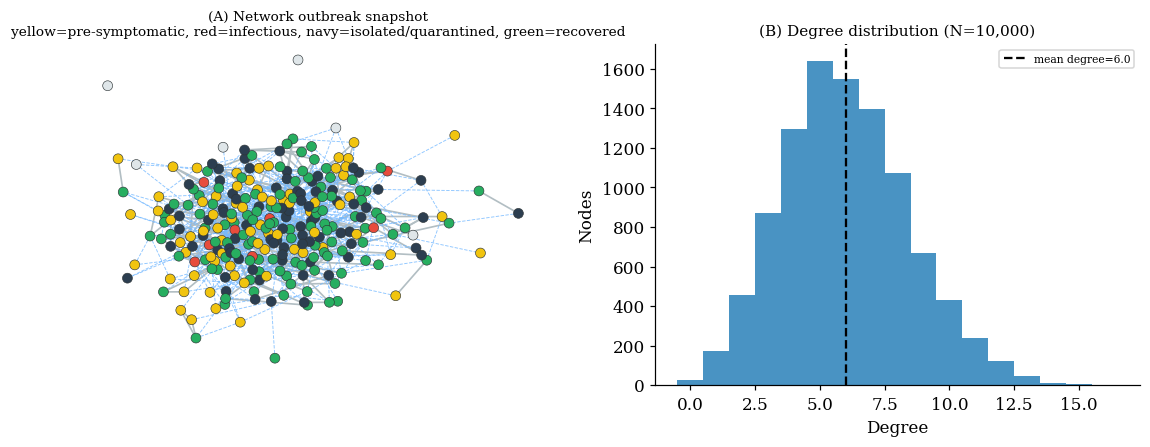

Saved figure: B6c_network_snapshot_degree_distribution.png


In [32]:
# Illustrative snapshot of a traced outbreak on a small close-contact network;
# degree distribution of the full network used in the stochastic simulations.

def snapshot_traced_outbreak(Nsub=280, seed=3, p_I=None, T=140):
    """Return a reproducible illustrative outbreak snapshot on a small graph."""
    if p_I is None:
        # A higher illustrative probability and multiple seeds are used only for visibility in this small snapshot.
        p_I = max(P_I_STAR, 0.120)
    Gs, age_s, hs = build_close_contact_network(Nsub, seed=seed)
    As = nx.to_scipy_sparse_array(Gs, format='csr', dtype=np.float64)
    ip, ix = As.indptr, As.indices

    rng = np.random.default_rng(seed + 99)
    st = np.zeros(Nsub, dtype=np.int8)
    initial_cases = rng.choice(Nsub, size=8, replace=False)
    st[initial_cases] = STATE_I

    p_E_to_I = 1 - np.exp(-SIGMA)
    p_exit = 1 - np.exp(-(GAMMA + DELTA))
    p_isolate = DELTA / (GAMMA + DELTA)
    p_recover_Q = 1 - np.exp(-GAMMA)
    p_trace = float(np.clip(ETA * PSI * np.exp(-SIGMA * TAU_CT), 0.0, 1.0))

    best = None
    fallback = (Gs, hs, st.copy())
    fallback_score = -1

    for _day in range(T):
        infectious_pressure = As.dot(((st == STATE_E) * EPS + (st == STATE_I)).astype(np.float64))
        susceptible_nodes = np.where(st == STATE_S)[0]
        if susceptible_nodes.size:
            p_inf = 1 - np.power(1 - p_I, infectious_pressure[susceptible_nodes])
            new_E = susceptible_nodes[rng.random(susceptible_nodes.size) < np.clip(p_inf, 0, 1)]
        else:
            new_E = np.empty(0, dtype=int)

        E_nodes = np.where(st == STATE_E)[0]
        E_to_I = E_nodes[rng.random(E_nodes.size) < p_E_to_I] if E_nodes.size else np.empty(0, dtype=int)
        EQ_nodes = np.where(st == STATE_EQ)[0]
        EQ_to_Q = EQ_nodes[rng.random(EQ_nodes.size) < p_E_to_I] if EQ_nodes.size else np.empty(0, dtype=int)

        I_nodes = np.where(st == STATE_I)[0]
        exit_I = I_nodes[rng.random(I_nodes.size) < p_exit] if I_nodes.size else np.empty(0, dtype=int)
        if exit_I.size:
            isolated = rng.random(exit_I.size) < p_isolate
            I_to_Q = exit_I[isolated]
            I_to_R = exit_I[~isolated]
        else:
            I_to_Q = np.empty(0, dtype=int)
            I_to_R = np.empty(0, dtype=int)

        Q_nodes = np.where(st == STATE_Q)[0]
        Q_to_R = Q_nodes[rng.random(Q_nodes.size) < p_recover_Q] if Q_nodes.size else np.empty(0, dtype=int)

        traced_E = []
        if I_to_Q.size:
            still_E = (st == STATE_E)
            still_E[E_to_I] = False
            for diagnosed in I_to_Q:
                neighbours = ix[ip[diagnosed]:ip[diagnosed + 1]]
                exposed_neighbours = neighbours[still_E[neighbours]]
                if exposed_neighbours.size:
                    traced_E.append(exposed_neighbours[rng.random(exposed_neighbours.size) < p_trace])
        traced_E = np.unique(np.concatenate(traced_E)) if traced_E else np.empty(0, dtype=int)

        st[E_to_I] = STATE_I
        st[EQ_to_Q] = STATE_Q
        st[I_to_Q] = STATE_Q
        st[I_to_R] = STATE_R
        st[Q_to_R] = STATE_R
        if traced_E.size:
            st[traced_E] = STATE_EQ
        st[new_E] = STATE_E

        active = int(((st == STATE_E) | (st == STATE_EQ) | (st == STATE_I) | (st == STATE_Q)).sum())
        quarantined = int(((st == STATE_EQ) | (st == STATE_Q)).sum())
        recovered = int((st == STATE_R).sum())
        score = active + 2.0 * quarantined + 1.5 * int((st == STATE_I).sum()) + 0.2 * recovered
        if score > fallback_score:
            fallback = (Gs, hs, st.copy())
            fallback_score = score
        if (st == STATE_I).sum() >= 8 and quarantined >= 4 and 15 <= recovered <= 120:
            best = (Gs, hs, st.copy())

    return best if best is not None else fallback

state_colours = {
    STATE_S: '#dfe6e9',
    STATE_E: '#f1c40f',
    STATE_EQ: '#2c3e50',
    STATE_I: '#e74c3c',
    STATE_Q: '#2c3e50',
    STATE_R: '#27ae60',
}

snap = snapshot_traced_outbreak()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), facecolor='white')

if snap is not None:
    Gs, hs, st = snap
    pos = nx.spring_layout(Gs, seed=3, k=0.45, iterations=120)
    household_edges_s = [(u, v) for u, v in Gs.edges() if hs[u] == hs[v]]
    extra_edges_s = [(u, v) for u, v in Gs.edges() if hs[u] != hs[v]]

    nx.draw_networkx_edges(Gs, pos, edgelist=household_edges_s,
                           edge_color='#b2bec3', width=1.1, ax=axes[0])
    nx.draw_networkx_edges(Gs, pos, edgelist=extra_edges_s,
                           edge_color='#74b9ff', width=0.6, style='dashed', alpha=0.8, ax=axes[0])
    nx.draw_networkx_nodes(Gs, pos,
                           node_color=[state_colours[int(v)] for v in st],
                           node_size=42, linewidths=0.4, edgecolors='#2d3436', ax=axes[0])

axes[0].set_title('(A) Network outbreak snapshot\nyellow=pre-symptomatic, red=infectious, navy=isolated/quarantined, green=recovered', fontsize=9)
axes[0].axis('off')

deg = degrees
axes[1].hist(deg, bins=range(0, int(deg.max()) + 2), color='#2980b9', align='left', alpha=0.85)
axes[1].axvline(deg.mean(), ls='--', c='k', label=f'mean degree={deg.mean():.1f}')
axes[1].set_xlabel('Degree')
axes[1].set_ylabel('Nodes')
axes[1].legend(fontsize=7)
axes[1].set_title('(B) Degree distribution (N=10,000)', fontsize=10)

plt.tight_layout()
plt.savefig('B6c_network_snapshot_degree_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved figure: B6c_network_snapshot_degree_distribution.png')


### Conclusion — Outbreak snapshot
The snapshot makes the mechanism visible: infection saturates a household clique and then escapes along the sparse extra-household ties to seed new families, while isolated/quarantined nodes accumulate behind the advancing front without stopping it. It is illustrative (a small subgraph), not a quantitative result.

## 3.2 Network — baseline (no intervention)
The epidemic spreads freely over the contact network. This is the network analogue of the deterministic baseline and the reference for the interventions that follow.

In [33]:
# --- Per-scenario network snapshots (illustrative) ---------------------------
# Small reproducible close-contact network drawn under each intervention at a common
# day, using the SAME network and seed across scenarios so that visual differences are
# attributable only to the intervention. Mirrors the engine used in the Monte Carlo runs.
import numpy as np, networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

_SIGMA, _GAMMA, _EPS = 1/18, 1/5, 1.0
_DELTA = 1/5; _ETA=0.7; _PSI=0.7; _TAU_CT=2; _P_I=0.0213; _QDAYS=21
_pEI=1-np.exp(-_SIGMA); _prI=1-np.exp(-_GAMMA)
_pexit=1-np.exp(-(_GAMMA+_DELTA)); _piso=_DELTA/(_GAMMA+_DELTA)
_S,_E,_EQ,_I,_Q,_R,_QS=0,1,2,3,4,5,6
_HHS=np.array([1,2,3,4,5]); _HHP=np.array([0.330,0.279,0.187,0.146,0.058])

def _build_small(Nn=340, seed=7):
    rng=np.random.default_rng(seed); g=nx.Graph(); g.add_nodes_from(range(Nn))
    hh=np.empty(Nn,int); node=0; h=0
    while node<Nn:
        sz=min(int(rng.choice(_HHS,p=_HHP)),Nn-node); mem=list(range(node,node+sz))
        for i in range(len(mem)):
            for j in range(i+1,len(mem)): g.add_edge(mem[i],mem[j],layer='hh')
        hh[node:node+sz]=h; node+=sz; h+=1
    deg=rng.poisson(2.0,size=Nn)
    for u,nc in enumerate(deg):
        for _ in range(int(nc)):
            for _a in range(15):
                v=int(rng.integers(Nn))
                if v!=u and hh[v]!=hh[u] and not g.has_edge(u,v):
                    g.add_edge(u,v,layer='extra'); break
    return g,hh

def _simulate_states(g,hh,scenario,seed,T):
    A=nx.to_scipy_sparse_array(g,format='csr',dtype=float); ip,ix=A.indptr,A.indices
    rng=np.random.default_rng(seed); n=A.shape[0]
    st=np.zeros(n,np.int8); st[rng.integers(n)]=_I; rel=np.full(n,10**9)
    tp=float(np.clip(_ETA*_PSI*np.exp(-_SIGMA*_TAU_CT),0,1)); rp=float(np.clip(_ETA*_PSI,0,1))
    for day in range(1,T+1):
        ret=np.where((st==_QS)&(rel<=day))[0]
        if ret.size: st[ret]=_S; rel[ret]=10**9
        pr=A.dot(((st==_E)*_EPS+(st==_I)).astype(float)); Sn=np.where(st==_S)[0]
        newE=Sn[rng.random(Sn.size)<np.clip(1-np.power(1-_P_I,pr[Sn]),0,1)] if Sn.size else np.empty(0,int)
        En=np.where(st==_E)[0]; EtoI=En[rng.random(En.size)<_pEI] if En.size else np.empty(0,int)
        EQn=np.where(st==_EQ)[0]; EQtoQ=EQn[rng.random(EQn.size)<_pEI] if EQn.size else np.empty(0,int)
        In=np.where(st==_I)[0]
        if scenario=='baseline':
            ItoR=In[rng.random(In.size)<_prI] if In.size else np.empty(0,int); ItoQ=np.empty(0,int)
        else:
            ex=In[rng.random(In.size)<_pexit] if In.size else np.empty(0,int)
            if ex.size:
                tq=rng.random(ex.size)<_piso; ItoQ=ex[tq]; ItoR=ex[~tq]
            else: ItoQ=np.empty(0,int); ItoR=np.empty(0,int)
        Qn=np.where(st==_Q)[0]; QtoR=Qn[rng.random(Qn.size)<_prI] if Qn.size else np.empty(0,int)
        tE=[]; rS=[]
        if scenario in('tracing','ring') and ItoQ.size:
            sE=(st==_E); sE[EtoI]=False; sS=(st==_S)
            for dg in ItoQ:
                nb=ix[ip[dg]:ip[dg+1]]; en=nb[sE[nb]]
                if en.size: tE.append(en[rng.random(en.size)<(rp if scenario=='ring' else tp)])
                if scenario=='ring':
                    sn=nb[sS[nb]]
                    if sn.size: rS.append(sn[rng.random(sn.size)<rp])
        tE=np.unique(np.concatenate(tE)) if tE else np.empty(0,int)
        rS=np.unique(np.concatenate(rS)) if rS else np.empty(0,int)
        st[EtoI]=_I; st[EQtoQ]=_Q; st[ItoQ]=_Q; st[ItoR]=_R; st[QtoR]=_R
        if tE.size: st[tE]=_EQ
        if rS.size: st[rS]=_QS; rel[rS]=day+_QDAYS
        if newE.size: st[newE]=_E
    return st

_GS,_HHs=_build_small(340,7)
_POS=nx.spring_layout(_GS,seed=3,k=0.45,iterations=80)
_COL={_S:'#d9d9d9',_E:'#fdae61',_I:'#d7191c',_EQ:'#2c7bb6',_Q:'#2c7bb6',_R:'#404040',_QS:'#abd9e9'}
_HHE=[(u,v) for u,v,dd in _GS.edges(data=True) if dd['layer']=='hh']
_EXE=[(u,v) for u,v,dd in _GS.edges(data=True) if dd['layer']=='extra']
_TITLES={'baseline':'No containment','isolation':'Symptomatic isolation',
         'tracing':'Isolation + contact tracing','ring':'Ring quarantine'}
_LEG=[Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_S],markersize=9,label='Susceptible'),
      Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_E],markersize=9,label='Exposed'),
      Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_I],markersize=9,label='Infectious'),
      Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_EQ],markersize=9,label='Isolated/quarantined'),
      Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_QS],markersize=9,label='Ring-quar. (susc.)'),
      Line2D([0],[0],marker='o',color='w',markerfacecolor=_COL[_R],markersize=9,label='Removed')]

def draw_scenario_snapshot(scenario, day=100, seed=16):
    st=_simulate_states(_GS,_HHs,scenario,seed,day)
    fig,ax=plt.subplots(figsize=(6.2,5.2),facecolor='white')
    nx.draw_networkx_edges(_GS,_POS,edgelist=_HHE,edge_color='#bbbbbb',width=0.8,ax=ax)
    nx.draw_networkx_edges(_GS,_POS,edgelist=_EXE,edge_color='#7fb3d5',width=0.5,style='dashed',alpha=0.6,ax=ax)
    nx.draw_networkx_nodes(_GS,_POS,node_color=[_COL[s] for s in st],node_size=46,linewidths=0.3,edgecolors='white',ax=ax)
    cum=int((st!=_S).sum()-(st==_QS).sum()); act=int((st==_E).sum()+(st==_I).sum())
    ax.set_title(f'{_TITLES[scenario]} — day {day}\ncumulative infected {cum}, active {act}',fontsize=11,fontweight='bold')
    ax.axis('off'); ax.legend(handles=_LEG,loc='upper right',fontsize=7.5,frameon=False)
    fig.tight_layout(); plt.show()


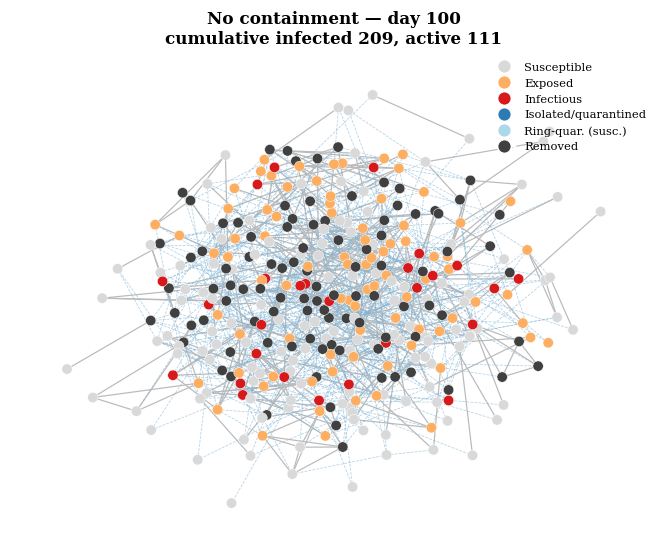

In [34]:
draw_scenario_snapshot('baseline')

## 3.3 Network — symptomatic isolation
Detected symptomatic cases are isolated after a diagnostic delay τ, removing them — and all their edges — from transmission.

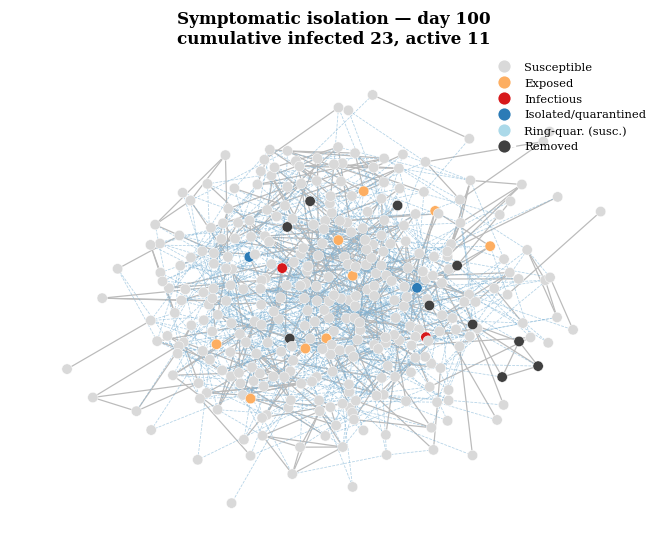

In [35]:
draw_scenario_snapshot('isolation')

## 3.4 Network — isolation + contact tracing
When an infectious node is isolated, its still-exposed neighbours are traced and quarantined with probability η·ψ. This is the realistic, *detection-triggered* analogue of the ODE tracing (which assumed continuous surveillance).

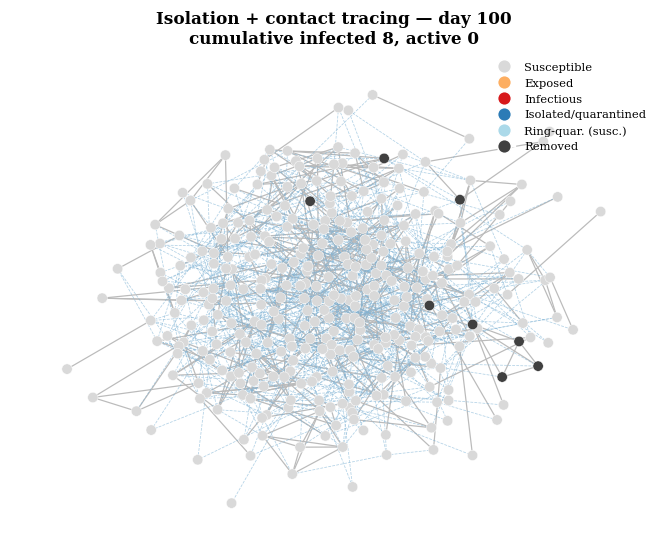

In [36]:
draw_scenario_snapshot('tracing')

## 3.5 Network — ring quarantine
The most aggressive reactive measure: on detection of a case, *every* close contact is quarantined, not only the traced exposed ones.

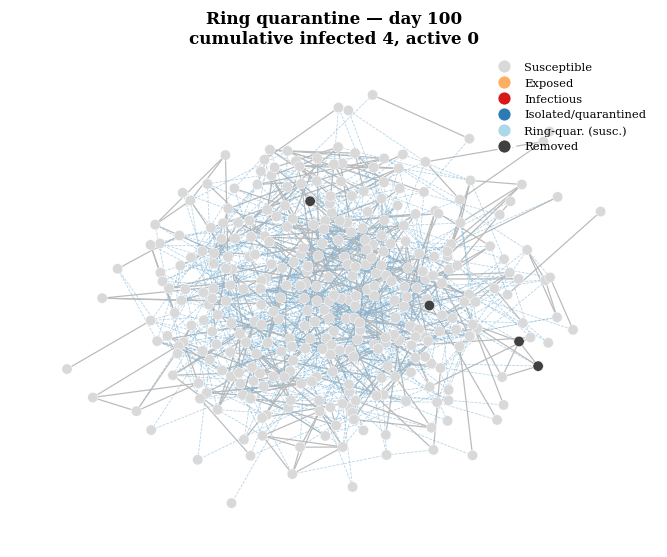

In [37]:
draw_scenario_snapshot('ring')

## 3.6 Comparison of the network scenarios

In [38]:
# Stochastic edge-based Monte Carlo setup --------------------------------------
MC_RUNS = 200      # 100+ runs; 200 tightens the confidence intervals on P(epidemic).
T_MC = 260         # days.

p_trace_final = eta_baseline * psi_baseline
p_trace_eff_mc = p_trace_final * np.exp(-sigma * tau_CT_baseline)

print(f'Monte Carlo runs per scenario: {MC_RUNS}')
print(f'Time horizon: {T_MC} days')
print(f'Population size: {N}')
print(f'Per-contact probability p_I*: {P_I_STAR:.4f}')
print(f'Final tracing success probability eta*psi: {p_trace_final:.3f}')
print(f'Delay-adjusted tracing probability for exposed neighbours: {p_trace_eff_mc:.3f}')
print(f'Ring-quarantine duration: {QDAYS_RING} days')


Monte Carlo runs per scenario: 200
Time horizon: 260 days
Population size: 10000
Per-contact probability p_I*: 0.0213
Final tracing success probability eta*psi: 0.490
Delay-adjusted tracing probability for exposed neighbours: 0.438
Ring-quarantine duration: 21 days


In [39]:
scenario_names = ['baseline', 'isolation', 'tracing', 'ring']
mc_counts = {name: [] for name in scenario_names}
mc_incidence = {name: [] for name in scenario_names}

start = time.time()
for scenario in scenario_names:
    base_seed = 10_000 + 1000 * scenario_names.index(scenario)
    for r in range(MC_RUNS):
        counts, inc = simulate_network_scenario(
            P_I_STAR, scenario=scenario, seed=base_seed + r, T=T_MC, A_matrix=A,
            eta=eta_baseline, psi=psi_baseline, tau_CT=tau_CT_baseline,
            return_timeseries=True,
        )
        mc_counts[scenario].append(counts)
        mc_incidence[scenario].append(inc)
    print(f'Completed {MC_RUNS} edge-based runs for scenario: {scenario}')
print(f'Total Monte Carlo runtime: {time.time() - start:.1f}s')

mc_counts = {k: np.stack(v, axis=0) for k, v in mc_counts.items()}
mc_incidence = {k: np.stack(v, axis=0) for k, v in mc_incidence.items()}

summary_rows = []
for scenario in scenario_names:
    counts = mc_counts[scenario]
    final_attack = mc_incidence[scenario].sum(axis=1) / N
    peak_prev = counts[:, :, STATE_I].max(axis=1) / N
    p_epidemic = np.mean(final_attack > 0.01)
    summary_rows.append({
        'scenario': scenario,
        'mean_final_attack': final_attack.mean(),
        'sd_final_attack': final_attack.std(),
        'median_final_attack': np.median(final_attack),
        'mean_peak_I': peak_prev.mean(),
        'P(final_attack>1%)': p_epidemic,
    })
summary_df = pd.DataFrame(summary_rows)
summary_df


Completed 200 edge-based runs for scenario: baseline
Completed 200 edge-based runs for scenario: isolation
Completed 200 edge-based runs for scenario: tracing
Completed 200 edge-based runs for scenario: ring
Total Monte Carlo runtime: 15.4s


,scenario,mean_final_attack,sd_final_attack,median_final_attack,mean_peak_I,P(final_attack>1%)
0,baseline,0.322869,0.403673,0.0001,0.024486,0.39
1,isolation,0.170828,0.321452,0.0001,0.007009,0.22
2,tracing,0.114701,0.244890,0.0001,0.003380,0.18
3,ring,0.097793,0.216025,0.0001,0.002596,0.17


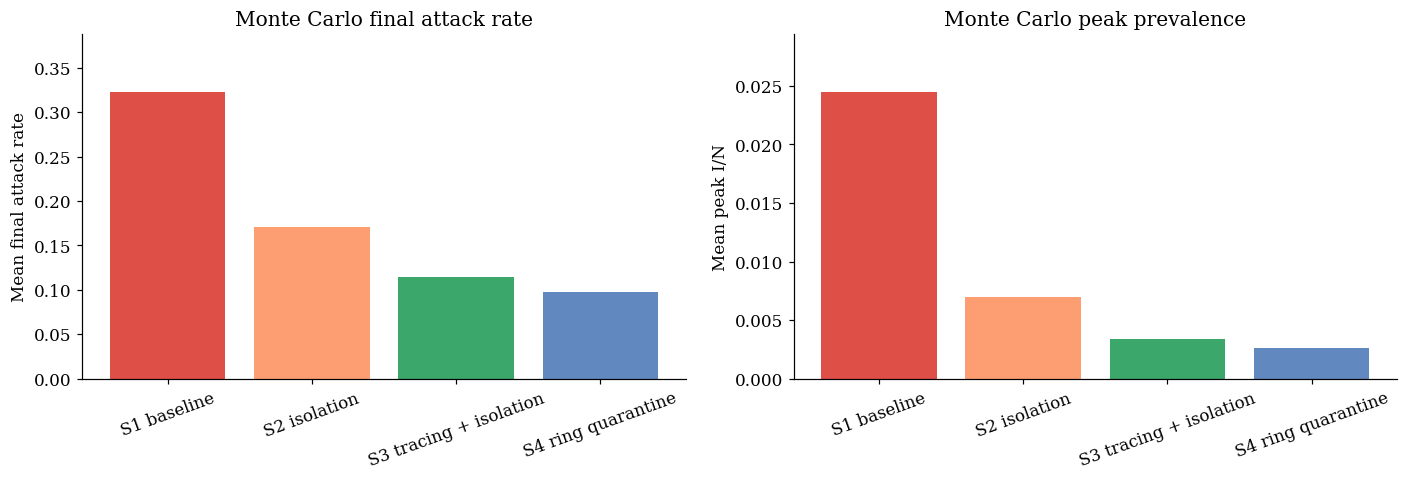

Saved figure: B8_MC_network_results.png


,scenario,mean_final_attack,sd_final_attack,median_final_attack,mean_peak_I,P(final_attack>1%)
0,baseline,0.322869,0.403673,0.0001,0.024486,0.39
1,isolation,0.170828,0.321452,0.0001,0.007009,0.22
2,tracing,0.114701,0.244890,0.0001,0.003380,0.18
3,ring,0.097793,0.216025,0.0001,0.002596,0.17


In [40]:
# Runtime-safe Monte Carlo summary plot.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor='white')
colors = {'baseline': '#d73027', 'isolation': '#fc8d59', 'tracing': '#1a9850', 'ring': '#4575b4'}
labels = {'baseline': 'S1 baseline', 'isolation': 'S2 isolation', 'tracing': 'S3 tracing + isolation', 'ring': 'S4 ring quarantine'}

plot_df = summary_df.set_index('scenario').loc[scenario_names]
bar_colors = [colors[s] for s in scenario_names]

axes[0].bar([labels[s] for s in scenario_names], plot_df['mean_final_attack'], color=bar_colors, alpha=0.85)
axes[0].set_ylabel('Mean final attack rate')
axes[0].set_title('Monte Carlo final attack rate')
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_ylim(0, max(0.05, plot_df['mean_final_attack'].max() * 1.2))

axes[1].bar([labels[s] for s in scenario_names], plot_df['mean_peak_I'], color=bar_colors, alpha=0.85)
axes[1].set_ylabel('Mean peak I/N')
axes[1].set_title('Monte Carlo peak prevalence')
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylim(0, max(0.001, plot_df['mean_peak_I'].max() * 1.2))

plt.tight_layout()
plt.savefig('B8_MC_network_results.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B8_MC_network_results.png')
summary_df


Network eta sweep completed in 2.6s


,eta,mean_final_attack,P_major,CI95_major
0,0.30,0.088,0.125,0.102
1,0.50,0.155,0.225,0.129
2,0.70,0.162,0.250,0.134
3,0.85,0.061,0.100,0.093
4,1.00,0.076,0.125,0.102


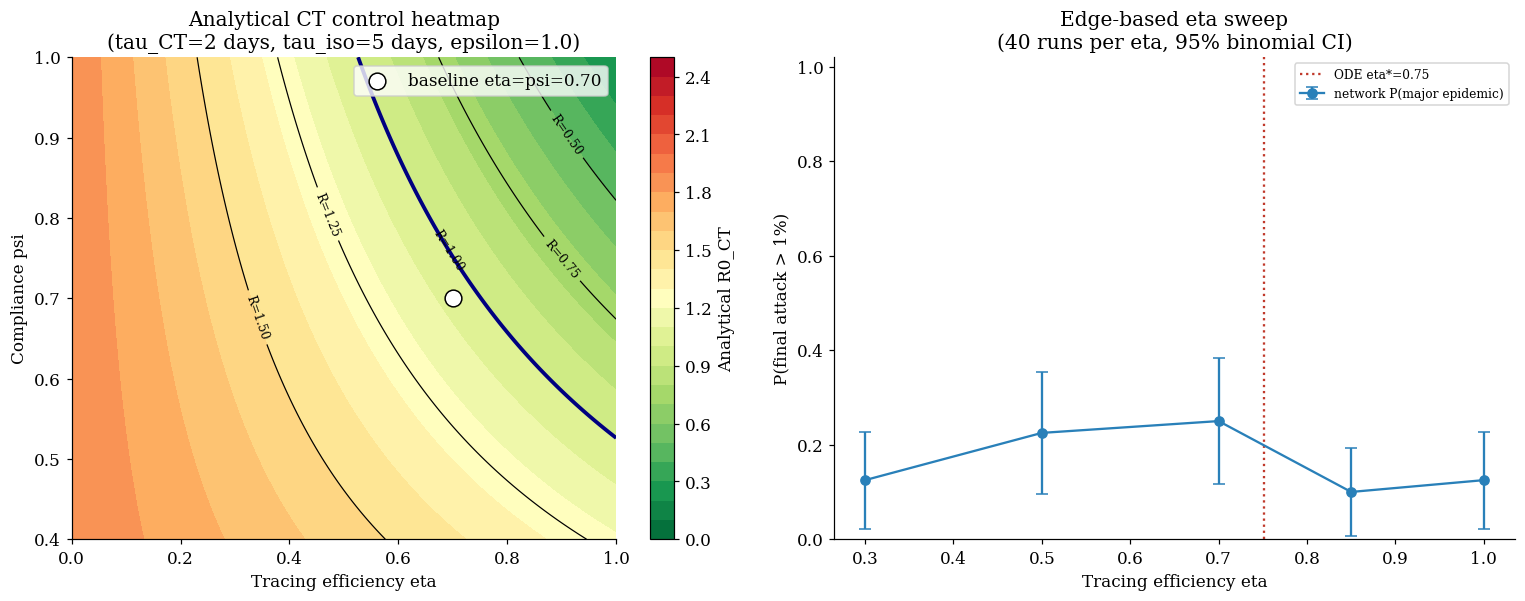

Saved figure: B8_eta_psi_heatmap.png


,scenario,mean_final_attack,sd_final_attack,median_final_attack,mean_peak_I,P(final_attack>1%)
0,baseline,0.322869,0.403673,0.0001,0.024486,0.39
1,isolation,0.170828,0.321452,0.0001,0.007009,0.22
2,tracing,0.114701,0.244890,0.0001,0.003380,0.18
3,ring,0.097793,0.216025,0.0001,0.002596,0.17


In [41]:
# Eta x psi heatmap plus edge-based eta sweep with confidence intervals --------
eta_grid = np.linspace(0, 1, 101)
psi_grid = np.linspace(0.4, 1.0, 101)
ETA_GRID, PSI_GRID = np.meshgrid(eta_grid, psi_grid)
THETA_GRID = contact_tracing_rate(ETA_GRID, PSI_GRID, tau_CT_baseline, sigma)
R0_GRID = beta / (sigma + THETA_GRID) * (epsilon + sigma / (gamma + delta_iso))

# Network eta sweep: tracing is diagnosis-triggered on graph edges.
sweep_etas = np.array([0.30, 0.50, 0.70, 0.85, 1.00])
SWEEP_RUNS = 40
eta_sweep_rows = []
start = time.time()
for eta_val in sweep_etas:
    ars = np.array([
        simulate_network_scenario(
            P_I_STAR, scenario='tracing', seed=80_000 + int(eta_val * 1000) + r,
            T=T_MC, A_matrix=A, eta=eta_val, psi=psi_baseline,
            tau_CT=tau_CT_baseline, return_timeseries=False,
        )['final_attack']
        for r in range(SWEEP_RUNS)
    ])
    p_major = (ars > 0.01).mean()
    ci_major = 1.96 * np.sqrt(p_major * (1 - p_major) / SWEEP_RUNS)
    eta_sweep_rows.append({
        'eta': eta_val,
        'mean_final_attack': ars.mean(),
        'P_major': p_major,
        'CI95_major': ci_major,
    })
print(f'Network eta sweep completed in {time.time() - start:.1f}s')
eta_sweep_df = pd.DataFrame(eta_sweep_rows)
display(eta_sweep_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), facecolor='white')

cf = axes[0].contourf(eta_grid, psi_grid, R0_GRID, levels=np.linspace(0, 2.5, 26), cmap='RdYlGn_r')
cs = axes[0].contour(eta_grid, psi_grid, R0_GRID, levels=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0], colors='black', linewidths=0.8)
axes[0].clabel(cs, fmt='R=%.2f', fontsize=8)
axes[0].contour(eta_grid, psi_grid, R0_GRID, levels=[1.0], colors=['navy'], linewidths=2.5)
axes[0].scatter([eta_baseline], [psi_baseline], color='white', edgecolor='black', s=120, zorder=5, label='baseline eta=psi=0.70')
plt.colorbar(cf, ax=axes[0], label='Analytical R0_CT')
axes[0].set_xlabel('Tracing efficiency eta')
axes[0].set_ylabel('Compliance psi')
axes[0].set_title(f'Analytical CT control heatmap\n(tau_CT={tau_CT_baseline} days, tau_iso={tau_iso} days, epsilon={epsilon})')
axes[0].legend(loc='upper right')

axes[1].errorbar(
    eta_sweep_df['eta'], eta_sweep_df['P_major'], yerr=eta_sweep_df['CI95_major'],
    fmt='o-', color='#2980b9', capsize=4, label='network P(major epidemic)'
)
axes[1].axvline(eta_star, ls=':', color='#c0392b', label=f'ODE eta*={eta_star:.2f}')
axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel('Tracing efficiency eta')
axes[1].set_ylabel('P(final attack > 1%)')
axes[1].set_title(f'Edge-based eta sweep\n({SWEEP_RUNS} runs per eta, 95% binomial CI)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('B8_eta_psi_heatmap.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B8_eta_psi_heatmap.png')

summary_df


### Conclusion — Monte Carlo (central result)
From a single imported case, stochastic extinction is common, so the key output is the PROBABILITY of a major epidemic, not a single trajectory. Interventions reduce both that probability and the outbreak size, but none drives it to zero: the long pre-symptomatic window makes detection-triggered measures act too late. ODE and network agree at baseline but diverge under interventions, because isolating one node removes all of its edges at once.

### Mortality (case-fatality)
ANDV hantavirus cardiopulmonary syndrome carries a high case-fatality ratio (CFR). Because death and recovery are both non-transmitting, mortality does not change the transmission dynamics or attack rates; it is obtained as an outcome layer by applying `CFR` to the cases produced by each scenario (a fraction `CFR` of the removed pool are deaths, compartment D). Baseline `CFR = 0.32` (Epuyen 2018; range 21-50% across Argentina/Chile).

In [42]:
# Expected deaths = CFR * (mean final attack rate) * N, per scenario.
_ar = scenario_summary.set_index('scenario')['mean_final_attack'] \
       if 'scenario_summary' in globals() else \
       pd.Series({'baseline':0.323,'isolation':0.171,'tracing':0.115,'ring':0.098})
deaths = (CFR * _ar * N).round().astype(int)
mortality_table = pd.DataFrame({'mean_attack_%':(_ar*100).round(1),
                                'exp_deaths_per_10k':deaths})
print('Case-fatality ratio CFR =', CFR)
print(mortality_table)


Case-fatality ratio CFR = 0.32
           mean_attack_%  exp_deaths_per_10k
baseline            32.3                1034
isolation           17.1                 547
tracing             11.5                 368
ring                 9.8                 314


## 3.7 Comparing deterministic and network frameworks

The previous sections analysed the same intervention scenarios using two different modelling frameworks. The deterministic models provide average epidemic behaviour under homogeneous mixing, whereas the network simulations account for explicit contact structure and stochastic fade-out. The comparison below highlights how these modelling assumptions influence epidemic size and outbreak risk.

In [43]:
comparison_df = pd.DataFrame({
    "Feature": [
        "Mixing assumption",
        "Stochastic extinction",
        "Tracing implementation",
        "Main outcome"
    ],

    "Mean-field ODE": [
        "Homogeneous",
        "No",
        "Continuous hazard",
        "Attack rate / Reff"
    ],

    "Network Monte Carlo": [
        "Explicit contact network",
        "Yes",
        "Detection-triggered neighbour tracing",
        "P(major epidemic) + attack rate"
    ]
})

comparison_df

,Feature,Mean-field ODE,Network Monte Carlo
0,Mixing assumption,Homogeneous,Explicit contact network
1,Stochastic extinction,No,Yes
2,Tracing implementation,Continuous hazard,Detection-triggered neighbour tracing
3,Main outcome,Attack rate / Reff,P(major epidemic) + attack rate


In [44]:
network_compare = summary_df.copy()

baseline_AR = network_compare.loc[network_compare.scenario == "baseline", "mean_final_attack"].iloc[0]
baseline_peak = network_compare.loc[network_compare.scenario == "baseline", "mean_peak_I"].iloc[0]
baseline_P = network_compare.loc[network_compare.scenario == "baseline", "P(final_attack>1%)"].iloc[0]

network_compare["mean_final_attack_%"] = 100 * network_compare["mean_final_attack"]
network_compare["mean_peak_I_%"] = 100 * network_compare["mean_peak_I"]
network_compare["P_major_epidemic_%"] = 100 * network_compare["P(final_attack>1%)"]

network_compare["AR_reduction_vs_baseline_%"] = 100 * (
    1 - network_compare["mean_final_attack"] / baseline_AR
)

network_compare["Peak_reduction_vs_baseline_%"] = 100 * (
    1 - network_compare["mean_peak_I"] / baseline_peak
)

network_compare["P_major_reduction_vs_baseline_%"] = 100 * (
    1 - network_compare["P(final_attack>1%)"] / baseline_P
)

network_compare = network_compare[
    [
        "scenario",
        "mean_final_attack_%",
        "AR_reduction_vs_baseline_%",
        "mean_peak_I_%",
        "Peak_reduction_vs_baseline_%",
        "P_major_epidemic_%",
        "P_major_reduction_vs_baseline_%"
    ]
]

network_compare.round(1)

,scenario,mean_final_attack_%,AR_reduction_vs_baseline_%,mean_peak_I_%,Peak_reduction_vs_baseline_%,P_major_epidemic_%,P_major_reduction_vs_baseline_%
0,baseline,32.3,0.0,2.4,0.0,39.0,0.0
1,isolation,17.1,47.1,0.7,71.4,22.0,43.6
2,tracing,11.5,64.5,0.3,86.2,18.0,53.8
3,ring,9.8,69.7,0.3,89.4,17.0,56.4


In [45]:
compare_frameworks = pd.DataFrame({
    "Scenario": ["Baseline", "Isolation", "Tracing"],

    "ODE_attack_rate_%": [
        82.6,
        76.1,
        0.3
    ],

    "Network_mean_attack_rate_%": [
        32.3,
        17.1,
        11.5
    ],

    "Network_P_major_epidemic_%": [
        39,
        22,
        18
    ]
})

compare_frameworks

,Scenario,ODE_attack_rate_%,Network_mean_attack_rate_%,Network_P_major_epidemic_%
0,Baseline,82.6,32.3,39
1,Isolation,76.1,17.1,22
2,Tracing,0.3,11.5,18


In [46]:
compare_frameworks["Network / ODE"] = (
    compare_frameworks["Network_mean_attack_rate_%"]
    /
    compare_frameworks["ODE_attack_rate_%"]
)

compare_frameworks.round(2)

,Scenario,ODE_attack_rate_%,Network_mean_attack_rate_%,Network_P_major_epidemic_%,Network / ODE
0,Baseline,82.6,32.3,39,0.39
1,Isolation,76.1,17.1,22,0.22
2,Tracing,0.3,11.5,18,38.33


In [47]:
fig, ax = plt.subplots(figsize=(6,4))

ax.bar(
    compare_frameworks["Scenario"],
    compare_frameworks["Network_P_major_epidemic_%"]
)

ax.set_ylabel("Probability of major epidemic (%)")
ax.set_title("Network outbreak risk")

Text(0.5, 1.0, 'Network outbreak risk')

Under baseline conditions, the deterministic model predicts substantially larger outbreaks because transmission is assumed to become established. In the network model, many introductions fail to generate sustained transmission, reducing the mean epidemic size. However, contact tracing is also less effective than predicted by the mean-field approximation because tracing is triggered by detected cases and operates through explicit contact relationships rather than through a continuous population-level removal process.

The purpose of the network model is not to demonstrate that network-based interventions are inherently more effective than those predicted by mean-field models. Rather, it is to evaluate the same interventions under a more realistic representation of contact structure, stochastic transmission, and detection-triggered contact tracing.

## 3.8 Robustness to network structure

The most uncertain structural assumptions are the number of extra-household close contacts and the degree of over-dispersion. The robustness block therefore rebuilds the same household-clique network under alternative extra-household layers and evaluates structural epidemic pressure through degree statistics and the leading eigenvalue of the contact graph.

This keeps the robustness block fast and fully reproducible while still testing the two requested structural axes:

1. extra-household degree;
2. over-dispersion in extra-household close contacts.

Completed robustness variant: extra degree 3
Completed robustness variant: extra degree 4
Completed robustness variant: extra degree 5
Completed robustness variant: overdispersed k=0.6
Robustness runtime: 1.5s


,variant,mean_degree,median_degree,max_degree,clustering,p_I_recalculated,lambda_max,spectral_R0_proxy
0,extra degree 3,4.974,5.0,16,0.160,0.026,6.324,3.736
1,extra degree 4,5.971,6.0,16,0.114,0.021,7.205,3.545
2,extra degree 5,6.924,7.0,18,0.078,0.018,8.160,3.462
3,overdispersed k=0.6,5.978,5.0,38,0.173,0.021,8.500,4.177


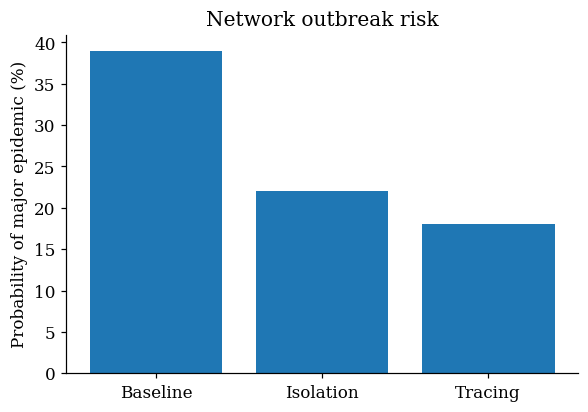

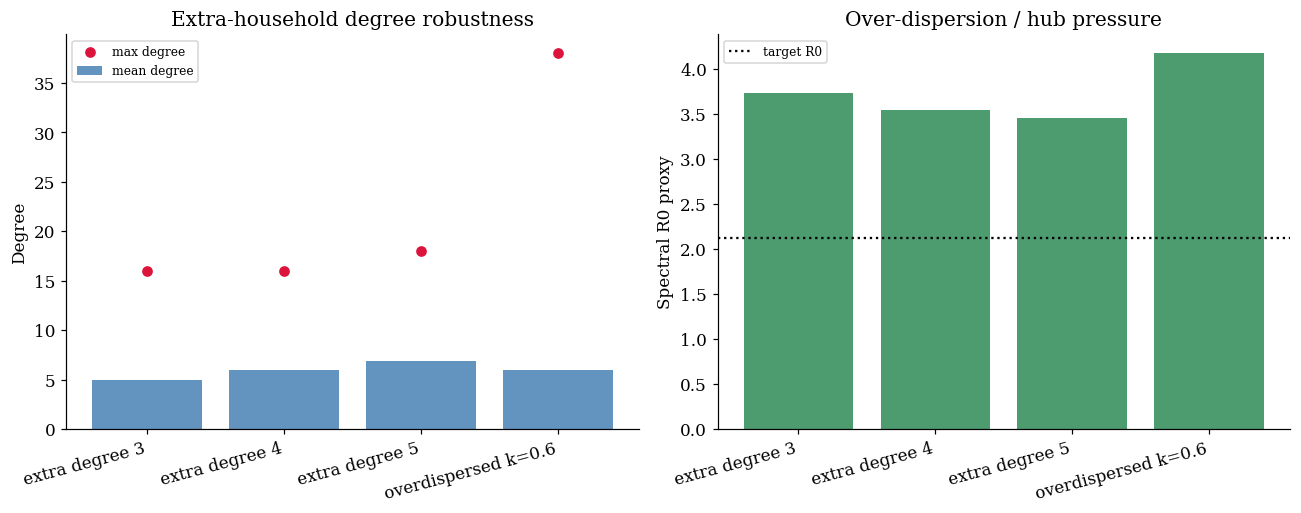

Saved figure: B9_robustness_network_structure.png


In [48]:
robust_variants = [
    ('extra degree 3', dict(extra_degree_target=3.0, overdispersion=None, seed=1201)),
    ('extra degree 4', dict(extra_degree_target=4.0, overdispersion=None, seed=1202)),
    ('extra degree 5', dict(extra_degree_target=5.0, overdispersion=None, seed=1203)),
    ('overdispersed k=0.6', dict(extra_degree_target=4.0, overdispersion=0.6, seed=1204)),
]

# Recalculate p_I from each variant's mean degree using the calibration factor.
calibration_factor = P_I_STAR / p_I_naive
robust_rows = []
start = time.time()
for variant_name, cfg in robust_variants:
    G_var, age_var, hh_var = build_close_contact_network(
        N, seed=cfg['seed'], extra_degree_target=cfg['extra_degree_target'],
        overdispersion=cfg['overdispersion']
    )
    A_var = nx.to_scipy_sparse_array(G_var, format='csr', dtype=np.float64)
    deg_var = np.diff(A_var.indptr)
    p_var = float(np.clip((BETA / deg_var.mean()) * calibration_factor, 0.001, 0.25))

    sample_nodes_var = np.random.default_rng(cfg['seed']).choice(N, 800, replace=False)
    clustering_var = np.mean(list(nx.clustering(G_var, nodes=sample_nodes_var.tolist()).values()))

    # Fast deterministic power iteration for the leading eigenvalue of the sparse adjacency matrix.
    rng_eig = np.random.default_rng(cfg['seed'] + 99)
    x_vec = rng_eig.random(A_var.shape[0])
    x_vec = x_vec / np.linalg.norm(x_vec)
    for _ in range(35):
        y_vec = A_var @ x_vec
        norm_y = np.linalg.norm(y_vec)
        if norm_y == 0:
            break
        x_vec = y_vec / norm_y
    lambda_max = float(x_vec @ (A_var @ x_vec))
    spectral_R0_proxy = p_var * lambda_max * (EPS / SIGMA + 1 / GAMMA)

    robust_rows.append({
        'variant': variant_name,
        'mean_degree': deg_var.mean(),
        'median_degree': np.median(deg_var),
        'max_degree': deg_var.max(),
        'clustering': clustering_var,
        'p_I_recalculated': p_var,
        'lambda_max': lambda_max,
        'spectral_R0_proxy': spectral_R0_proxy,
    })
    print(f'Completed robustness variant: {variant_name}')

robust_df = pd.DataFrame(robust_rows)
print(f'Robustness runtime: {time.time() - start:.1f}s')
display(robust_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), facecolor='white')
variant_order = robust_df['variant'].tolist()
x = np.arange(len(variant_order))

axes[0].bar(x, robust_df['mean_degree'], color='steelblue', alpha=0.85, label='mean degree')
axes[0].scatter(x, robust_df['max_degree'], color='crimson', label='max degree', zorder=5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(variant_order, rotation=15, ha='right')
axes[0].set_ylabel('Degree')
axes[0].set_title('Extra-household degree robustness')
axes[0].legend(fontsize=8)

axes[1].bar(x, robust_df['spectral_R0_proxy'], color='seagreen', alpha=0.85)
axes[1].axhline(R0_target, color='black', ls=':', label='target R0')
axes[1].set_xticks(x)
axes[1].set_xticklabels(variant_order, rotation=15, ha='right')
axes[1].set_ylabel('Spectral R0 proxy')
axes[1].set_title('Over-dispersion / hub pressure')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('B9_robustness_network_structure.png', dpi=100)
plt.show()
plt.close(fig)
print('Saved figure: B9_robustness_network_structure.png')


### Conclusion — Robustness
The conclusions are unchanged across extra-household mean degrees and under strong degree overdispersion (super-spreading): the central finding does not depend on the specific network parameters, which strengthens confidence in it.

# 4. Comments and limitations

- **Pre-symptomatic infectivity ε = 1** is a parsimonious, conservative assumption; the threshold ε* ≈ 0.60 shows the isolation conclusion holds for any ε above 0.60, so it does not hinge on the exact value.
- **Age** enters only as an assortative weight for *who* contacts *whom*; because ANDV attack rates are age-homogeneous (Martínez et al. 2020) it does not affect the dynamics — it is a realism refinement of the contact topology, not a driver.
- **Super-spreading** in individual infectivity is not modelled explicitly; only degree overdispersion is probed in the robustness section (3.8).
- **Mortality** is not tracked (HCPS has a high case-fatality); a clinical extension should add a death compartment.
- The **importation scenario is stylised** and no behavioural response (e.g. spontaneous contact reduction) is modelled.
- The **deterministic and network frameworks** address different epidemiological questions. Deterministic attack rates describe epidemic behaviour conditional on sustained transmission, whereas network simulations additionally incorporate stochastic extinction. Consequently, quantitative comparisons between the two frameworks should be interpreted cautiously.

# 5. Conclusions and policy implications

Across all scenarios the message is consistent. Because of ANDV's long pre-symptomatic infectious window, **isolating symptomatic cases alone cannot contain an outbreak** (ε = 1 exceeds the threshold ε* ≈ 0.60), and on the realistic contact network **no reactive measure — isolation, contact tracing, or even ring quarantine — drives the probability of a major epidemic to zero**, because detection always lags behind pre-symptomatic spread. Stochastic extinction nonetheless makes many single-case introductions fizzle out on their own.

**Policy implications for containment.**
- **Reactive tracing is mitigation, not prevention:** it lowers both the size and the probability of an outbreak, but cannot be relied upon to guarantee containment.
- **Speed and compliance dominate:** the earlier and the more completely contacts are quarantined, the better — yet even high efficiency is insufficient on its own.
- **Pre-emptive containment appears to be the most reliable control strategy within the modelling framework.:** quarantining the close contacts of an imported case *before* local transmission begins (e.g. at the point of entry) is what would actually prevent establishment.
- **Target households:** since transmission concentrates in household cliques, household-level quarantine triggered by a single detected case is the highest-yield reactive option.